<a href="https://colab.research.google.com/github/Haosheng333/SC5002-Lab-Assignment-2/blob/main/SC5002LabAssignment2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exercise 1, Question 1

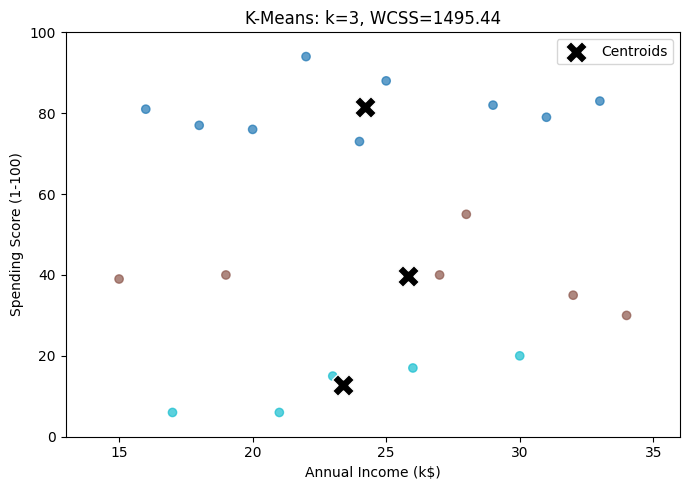


Cluster summary for k=3:
 Cluster  Customers  Mean Income  Mean Score
       0          9       24.222      81.444
       1          6       25.833      39.833
       2          5       23.400      12.800


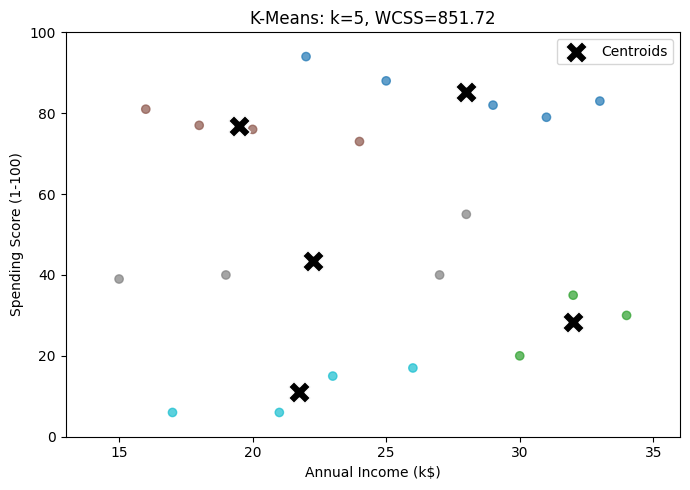


Cluster summary for k=5:
 Cluster  Customers  Mean Income  Mean Score
       0          5        28.00      85.200
       1          3        32.00      28.333
       2          4        19.50      76.750
       3          4        22.25      43.500
       4          4        21.75      11.000

Customer assignments (cluster numbers are arbitrary):
Customer  Income  Score  Cluster_k3  Cluster_k5
      C1    15.0   39.0           1           3
      C2    16.0   81.0           0           2
      C3    17.0    6.0           2           4
      C4    18.0   77.0           0           2
      C5    19.0   40.0           1           3
      C6    20.0   76.0           0           2
      C7    21.0    6.0           2           4
      C8    22.0   94.0           0           0
      C9    23.0   15.0           2           4
     C10    24.0   73.0           0           2
     C11    25.0   88.0           0           0
     C12    26.0   17.0           2           4
     C13    27.0   40.0  

In [ ]:
# Exercise 1, Question 1
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

RANDOM_STATE = 42

X_cluster = np.array([
    [15, 39], [16, 81], [17, 6], [18, 77], [19, 40],
    [20, 76], [21, 6], [22, 94], [23, 15], [24, 73],
    [25, 88], [26, 17], [27, 40], [28, 55], [29, 82],
    [30, 20], [31, 79], [32, 35], [33, 83], [34, 30]
], dtype=float)

assignments = pd.DataFrame({
    "Customer": [f"C{i}" for i in range(1, 21)],
    "Income": X_cluster[:, 0],
    "Score": X_cluster[:, 1]
})
results = []

for k in [3, 5]:
    kmeans = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=RANDOM_STATE
    )
    cluster_labels = kmeans.fit_predict(X_cluster)
    centers = kmeans.cluster_centers_
    assignments[f"Cluster_k{k}"] = cluster_labels
    results.append({"k": k, "WCSS": kmeans.inertia_})

    plt.figure(figsize=(7, 5))
    plt.scatter(
        X_cluster[:, 0], X_cluster[:, 1],
        c=cluster_labels, cmap="tab10", alpha=0.7
    )
    plt.scatter(
        centers[:, 0], centers[:, 1],
        marker="X", s=250, c="black",
        edgecolor="white", linewidth=1, label="Centroids"
    )
    plt.xlabel("Annual Income (k$)")
    plt.ylabel("Spending Score (1-100)")
    plt.title(f"K-Means: k={k}, WCSS={kmeans.inertia_:.2f}")
    plt.xlim(13, 36)
    plt.ylim(0, 100)
    plt.legend()
    plt.tight_layout()
    plt.show()

    print(f"\nCluster summary for k={k}:")
    print(pd.DataFrame({
        "Cluster": range(k),
        "Customers": np.bincount(cluster_labels, minlength=k),
        "Mean Income": centers[:, 0],
        "Mean Score": centers[:, 1]
    }).round(3).to_string(index=False))

print("\nCustomer assignments (cluster numbers are arbitrary):")
print(assignments.to_string(index=False))
print("\nWCSS comparison:")
print(pd.DataFrame(results).round(3).to_string(index=False))
print("\nk=3 gives broader customer groups; k=5 gives finer segmentation.")
print("A smaller WCSS at k=5 alone does not prove that five clusters are better,")
print("because increasing k generally reduces within-cluster squared distances.")


# Exercise 1, Question 2

 k      WCSS  WCSS decrease
 1 17886.200            NaN
 2  3306.000      14580.200
 3  1495.444       1810.556
 4  1170.944        324.500
 5   851.717        319.228
 6   635.050        216.667


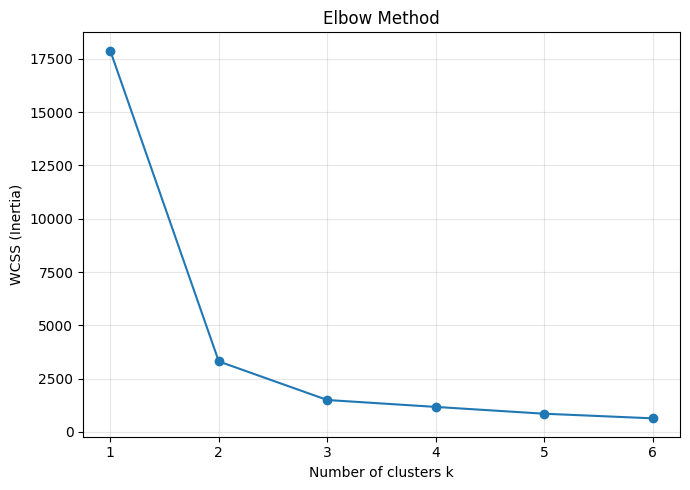


Suggested k from the elbow curve: 2
WCSS drops sharply from k=1 to k=2, then decreases more gradually.
k=2 is a reasonable elbow choice; k=3 offers finer segmentation.
The elbow method is a visual heuristic, not proof of a unique optimum.


In [ ]:
# Exercise 1, Question 2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

RANDOM_STATE = 42
X_cluster = np.array([
    [15, 39], [16, 81], [17, 6], [18, 77], [19, 40],
    [20, 76], [21, 6], [22, 94], [23, 15], [24, 73],
    [25, 88], [26, 17], [27, 40], [28, 55], [29, 82],
    [30, 20], [31, 79], [32, 35], [33, 83], [34, 30]
], dtype=float)

ks = range(1, 7)
inertias = []

for k in ks:
    km = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=RANDOM_STATE
    )
    labels = km.fit_predict(X_cluster)
    inertias.append(km.inertia_)

k_results = pd.DataFrame({"k": list(ks), "WCSS": inertias})
k_results["WCSS decrease"] = -k_results["WCSS"].diff()
print(k_results.round(3).to_string(index=False))

plt.figure(figsize=(7, 5))
plt.plot(list(ks), inertias, marker="o")
plt.xlabel("Number of clusters k")
plt.ylabel("WCSS (Inertia)")
plt.title("Elbow Method")
plt.xticks(list(ks))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

optimal_k = 2
print(f"\nSuggested k from the elbow curve: {optimal_k}")
print("WCSS drops sharply from k=1 to k=2, then decreases more gradually.")
print("k=2 is a reasonable elbow choice; k=3 offers finer segmentation.")
print("The elbow method is a visual heuristic, not proof of a unique optimum.")


# Exercise 1, Question 3

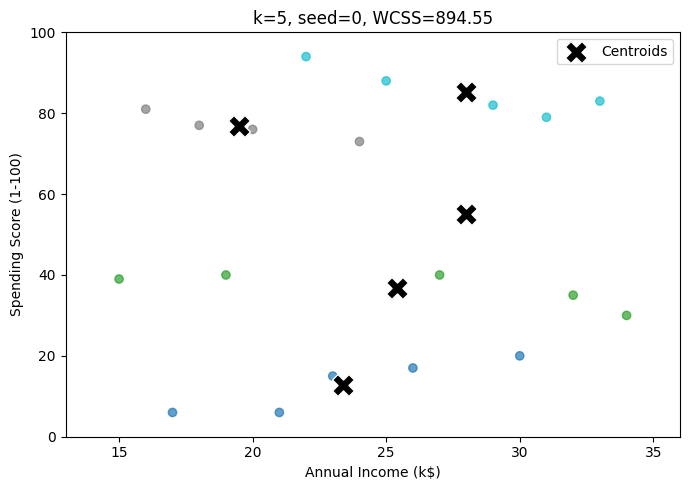

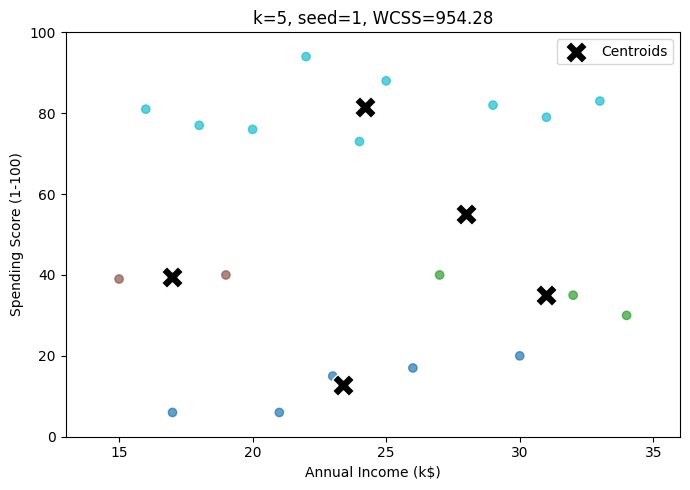

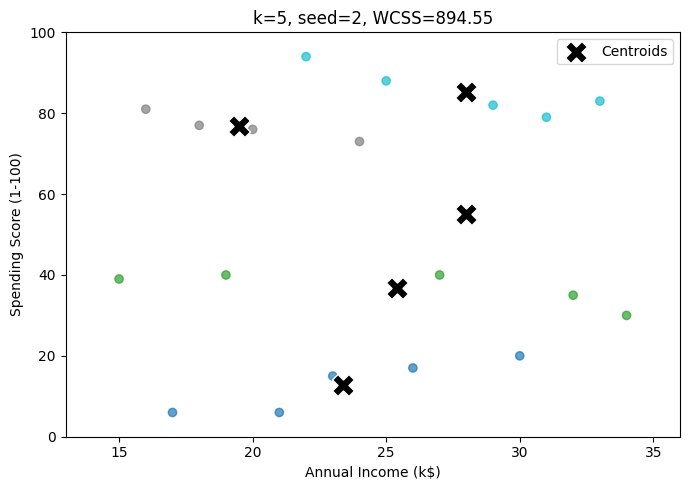

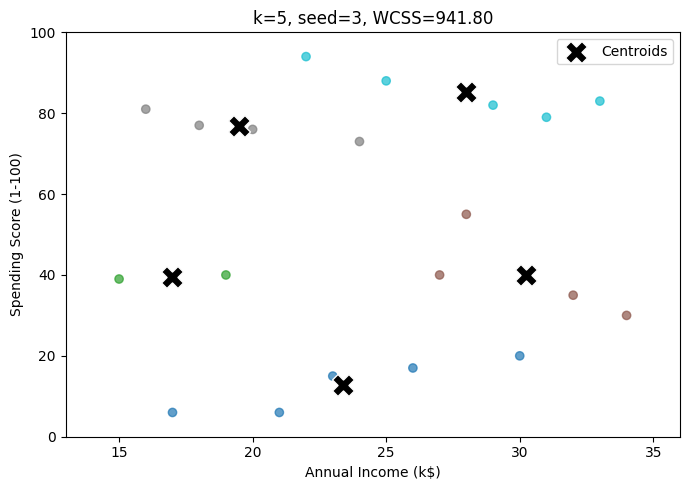

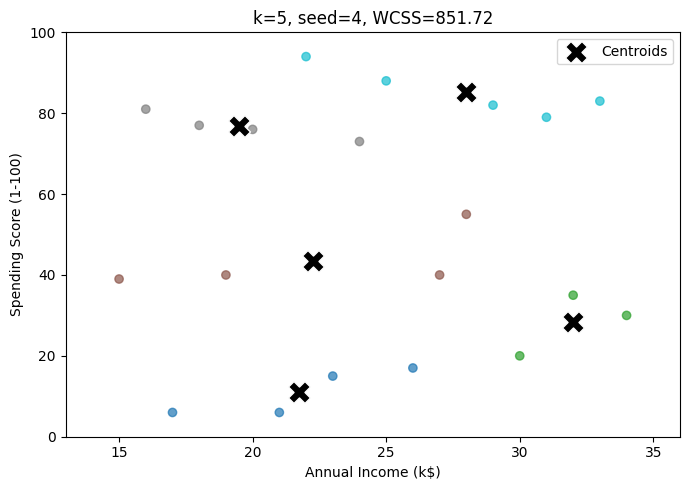


Customer assignments (IDs ordered by centroid spending score):
Customer  Seed_0  Seed_1  Seed_2  Seed_3  Seed_4
      C1       1       2       1       1       2
      C2       3       4       3       3       3
      C3       0       0       0       0       0
      C4       3       4       3       3       3
      C5       1       2       1       1       2
      C6       3       4       3       3       3
      C7       0       0       0       0       0
      C8       4       4       4       4       4
      C9       0       0       0       0       0
     C10       3       4       3       3       3
     C11       4       4       4       4       4
     C12       0       0       0       0       0
     C13       1       1       1       2       2
     C14       2       3       2       2       2
     C15       4       4       4       4       4
     C16       0       0       0       0       1
     C17       4       4       4       4       4
     C18       1       1       1       2       1
     

In [ ]:
# Exercise 1, Question 3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

X_cluster = np.array([
    [15, 39], [16, 81], [17, 6], [18, 77], [19, 40],
    [20, 76], [21, 6], [22, 94], [23, 15], [24, 73],
    [25, 88], [26, 17], [27, 40], [28, 55], [29, 82],
    [30, 20], [31, 79], [32, 35], [33, 83], [34, 30]
], dtype=float)

k = 5
seeds = [0, 1, 2, 3, 4]
results = []
assignments = pd.DataFrame({"Customer": [f"C{i}" for i in range(1, 21)]})
reference_labels = None

for seed in seeds:
    kmeans = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=1,
        random_state=seed
    )
    cluster_labels = kmeans.fit_predict(X_cluster)
    centers = kmeans.cluster_centers_

    order = np.argsort(centers[:, 1])
    label_map = np.empty(k, dtype=int)
    label_map[order] = np.arange(k)
    cluster_labels = label_map[cluster_labels]
    centers = centers[order]

    if reference_labels is None:
        reference_labels = cluster_labels.copy()

    ari = adjusted_rand_score(reference_labels, cluster_labels)
    assignments[f"Seed_{seed}"] = cluster_labels
    results.append({"Seed": seed, "WCSS": kmeans.inertia_, "ARI vs seed 0": ari})

    plt.figure(figsize=(7, 5))
    plt.scatter(
        X_cluster[:, 0], X_cluster[:, 1],
        c=cluster_labels, cmap="tab10", alpha=0.7, vmin=0, vmax=k - 1
    )
    plt.scatter(
        centers[:, 0], centers[:, 1],
        marker="X", s=250, c="black",
        edgecolor="white", linewidth=1, label="Centroids"
    )
    plt.xlabel("Annual Income (k$)")
    plt.ylabel("Spending Score (1-100)")
    plt.title(f"k={k}, seed={seed}, WCSS={kmeans.inertia_:.2f}")
    plt.xlim(13, 36)
    plt.ylim(0, 100)
    plt.legend()
    plt.tight_layout()
    plt.show()

print("\nCustomer assignments (IDs ordered by centroid spending score):")
print(assignments.to_string(index=False))
print("\nInitialization comparison:")
seed_results = pd.DataFrame(results)
print(seed_results.round(3).to_string(index=False))
print("ARI=1 means the same partition as seed 0, regardless of cluster IDs.")

if np.allclose(seed_results["ARI vs seed 0"], 1):
    print("\nThese seeds produced the same grouping; sensitivity was not observed here.")
else:
    print("\nThese seeds produced different groupings, demonstrating seed sensitivity.")
print("Different seeds can select different initial centroids, even with k-means++.")
print("K-Means may converge to different local minima, changing assignments and WCSS.")
print("n_init=10, as in the original notebook, keeps the best of ten runs and can")
print("reduce this variability, but does not guarantee the global optimum.")


# Exercise 2, Question 1

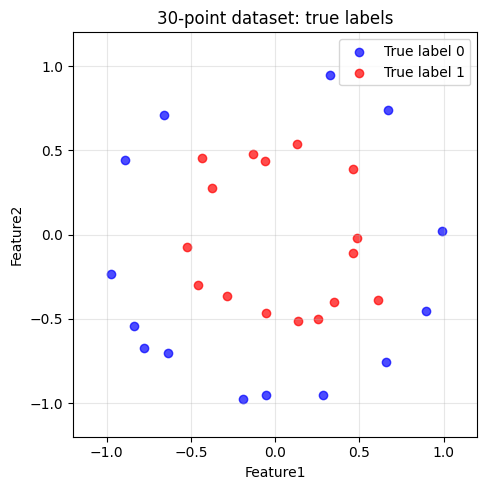

Number of points: 30
True label 0 (blue): 14
True label 1 (red): 16
The supplied coordinates form an approximate outer ring (0) and inner ring (1).


In [ ]:
# Exercise 2, Question 1
import numpy as np
import matplotlib.pyplot as plt

data = np.array([
    [ 0.1331, -0.5126, 1],
    [ 0.4648, -0.1070, 1],
    [-0.5205, -0.0741, 1],
    [ 0.4625,  0.3913, 1],
    [-0.9720, -0.2337, 0],
    [-0.8390, -0.5404, 0],
    [ 0.3491, -0.4034, 1],
    [-0.4556, -0.3020, 1],
    [ 0.2823, -0.9513, 0],
    [ 0.9885,  0.0195, 0],
    [-0.0522, -0.9507, 0],
    [-0.4315,  0.4549, 1],
    [ 0.1283,  0.5358, 1],
    [-0.0563, -0.4657, 1],
    [ 0.4846, -0.0224, 1],
    [-0.1881, -0.9745, 0],
    [ 0.3259,  0.9493, 0],
    [-0.8930,  0.4404, 0],
    [-0.7778, -0.6721, 0],
    [ 0.6570, -0.7580, 0],
    [-0.0618,  0.4373, 1],
    [ 0.6709,  0.7405, 0],
    [-0.6336, -0.7034, 0],
    [-0.2857, -0.3625, 1],
    [-0.1296,  0.4794, 1],
    [ 0.2557, -0.5007, 1],
    [-0.6574,  0.7107, 0],
    [ 0.8932, -0.4518, 0],
    [-0.3771,  0.2763, 1],
    [ 0.6122, -0.3904, 1]
], dtype=float)

X_cluster = data[:, :2]
true_labels = data[:, 2].astype(int)
# Keep the two original feature scales. Do not fit on the True Label column.

# Required colors: True Label 0 = blue; True Label 1 = red.
plt.figure(figsize=(7, 5))
for label, color in [(0, "blue"), (1, "red")]:
    mask = true_labels == label
    plt.scatter(
        X_cluster[mask, 0], X_cluster[mask, 1],
        c=color, alpha=0.7, label=f"True label {label}"
    )

plt.xlabel("Feature1")
plt.ylabel("Feature2")
plt.title("30-point dataset: true labels")
plt.gca().set_aspect("equal", adjustable="box")
plt.xlim(-1.2, 1.2)
plt.ylim(-1.2, 1.2)
plt.legend(loc="upper right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Number of points:", len(X_cluster))
print("True label 0 (blue):", np.sum(true_labels == 0))
print("True label 1 (red):", np.sum(true_labels == 1))
print("The supplied coordinates form an approximate outer ring (0) and inner ring (1).")


# Exercise 2, Question 2

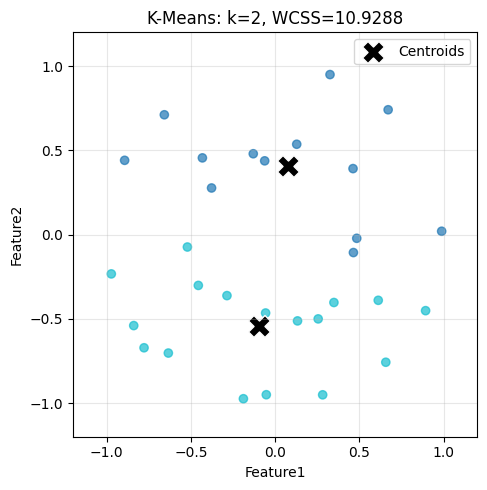

WCSS (Inertia): 10.928825

Cluster summary:
 Cluster  Count  Centroid Feature1  Centroid Feature2
       0     13              0.075             0.4082
       1     17             -0.094            -0.5440

Point assignments:
 Point  Feature1  Feature2  True Label  Cluster
     1    0.1331   -0.5126           1        1
     2    0.4648   -0.1070           1        0
     3   -0.5205   -0.0741           1        1
     4    0.4625    0.3913           1        0
     5   -0.9720   -0.2337           0        1
     6   -0.8390   -0.5404           0        1
     7    0.3491   -0.4034           1        1
     8   -0.4556   -0.3020           1        1
     9    0.2823   -0.9513           0        1
    10    0.9885    0.0195           0        0
    11   -0.0522   -0.9507           0        1
    12   -0.4315    0.4549           1        0
    13    0.1283    0.5358           1        0
    14   -0.0563   -0.4657           1        1
    15    0.4846   -0.0224           1        0
    16

In [ ]:
# Exercise 2, Question 2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

data = np.array([
    [ 0.1331, -0.5126, 1],
    [ 0.4648, -0.1070, 1],
    [-0.5205, -0.0741, 1],
    [ 0.4625,  0.3913, 1],
    [-0.9720, -0.2337, 0],
    [-0.8390, -0.5404, 0],
    [ 0.3491, -0.4034, 1],
    [-0.4556, -0.3020, 1],
    [ 0.2823, -0.9513, 0],
    [ 0.9885,  0.0195, 0],
    [-0.0522, -0.9507, 0],
    [-0.4315,  0.4549, 1],
    [ 0.1283,  0.5358, 1],
    [-0.0563, -0.4657, 1],
    [ 0.4846, -0.0224, 1],
    [-0.1881, -0.9745, 0],
    [ 0.3259,  0.9493, 0],
    [-0.8930,  0.4404, 0],
    [-0.7778, -0.6721, 0],
    [ 0.6570, -0.7580, 0],
    [-0.0618,  0.4373, 1],
    [ 0.6709,  0.7405, 0],
    [-0.6336, -0.7034, 0],
    [-0.2857, -0.3625, 1],
    [-0.1296,  0.4794, 1],
    [ 0.2557, -0.5007, 1],
    [-0.6574,  0.7107, 0],
    [ 0.8932, -0.4518, 0],
    [-0.3771,  0.2763, 1],
    [ 0.6122, -0.3904, 1]
], dtype=float)

X_cluster = data[:, :2]
true_labels = data[:, 2].astype(int)


RANDOM_STATE = 42

kmeans = KMeans(
    n_clusters=2,
    n_init=10,
    random_state=RANDOM_STATE
)
cluster_labels = kmeans.fit_predict(X_cluster)
centers = kmeans.cluster_centers_

plt.figure(figsize=(7, 5))
plt.scatter(
    X_cluster[:, 0], X_cluster[:, 1],
    c=cluster_labels, cmap="tab10", alpha=0.7
)
plt.scatter(
    centers[:, 0], centers[:, 1],
    marker="X", s=250, c="black",
    edgecolor="white", linewidth=1, label="Centroids"
)
plt.xlabel("Feature1")
plt.ylabel("Feature2")
plt.title(f"K-Means: k=2, WCSS={kmeans.inertia_:.4f}")
plt.gca().set_aspect("equal", adjustable="box")
plt.xlim(-1.2, 1.2)
plt.ylim(-1.2, 1.2)
plt.legend(loc="upper right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("WCSS (Inertia):", round(kmeans.inertia_, 6))
print("\nCluster summary:")
print(pd.DataFrame({
    "Cluster": [0, 1],
    "Count": np.bincount(cluster_labels, minlength=2),
    "Centroid Feature1": centers[:, 0],
    "Centroid Feature2": centers[:, 1]
}).round(4).to_string(index=False))

print("\nPoint assignments:")
print(pd.DataFrame({
    "Point": np.arange(1, 31),
    "Feature1": X_cluster[:, 0],
    "Feature2": X_cluster[:, 1],
    "True Label": true_labels,
    "Cluster": cluster_labels
}).to_string(index=False))
print("\nCluster IDs 0 and 1 are arbitrary; they need not match the true-label IDs.")
print("Only Feature1 and Feature2 were supplied to K-Means.")


# Exercise 2, Question 3

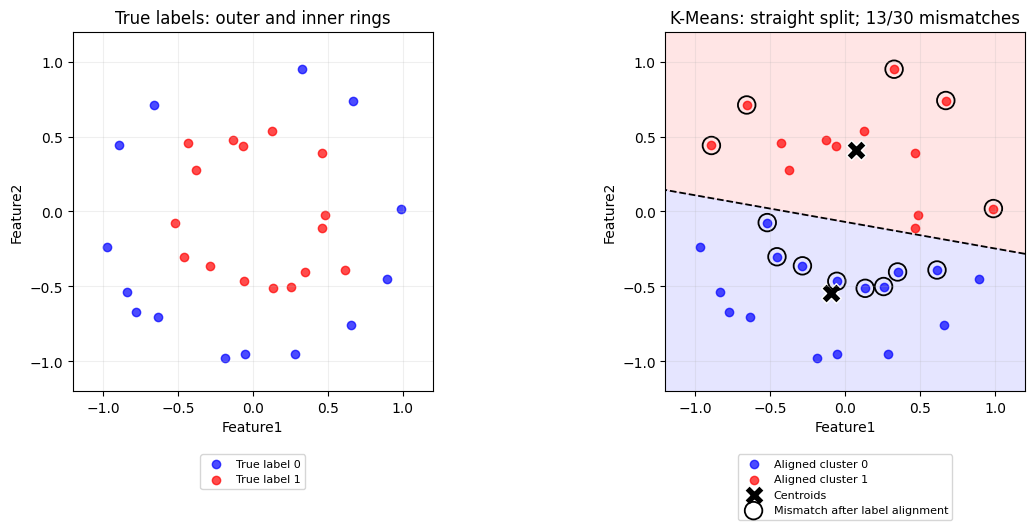

Best label-matched agreement: 56.67% (17/30)
Adjusted Rand Index (ARI): -0.0166
ARI=1 means identical partitions; a value near 0 indicates poor agreement.

True labels versus aligned K-Means clusters:
Aligned cluster  0  1
True label           
0                9  5
1                8  8

The dashed line is the nearest-centroid boundary.
Both predicted clusters contain points from both rings.
A straight split cannot separate an inner ring from a surrounding outer ring.


In [ ]:
# Exercise 2, Question 3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

data = np.array([
    [ 0.1331, -0.5126, 1],
    [ 0.4648, -0.1070, 1],
    [-0.5205, -0.0741, 1],
    [ 0.4625,  0.3913, 1],
    [-0.9720, -0.2337, 0],
    [-0.8390, -0.5404, 0],
    [ 0.3491, -0.4034, 1],
    [-0.4556, -0.3020, 1],
    [ 0.2823, -0.9513, 0],
    [ 0.9885,  0.0195, 0],
    [-0.0522, -0.9507, 0],
    [-0.4315,  0.4549, 1],
    [ 0.1283,  0.5358, 1],
    [-0.0563, -0.4657, 1],
    [ 0.4846, -0.0224, 1],
    [-0.1881, -0.9745, 0],
    [ 0.3259,  0.9493, 0],
    [-0.8930,  0.4404, 0],
    [-0.7778, -0.6721, 0],
    [ 0.6570, -0.7580, 0],
    [-0.0618,  0.4373, 1],
    [ 0.6709,  0.7405, 0],
    [-0.6336, -0.7034, 0],
    [-0.2857, -0.3625, 1],
    [-0.1296,  0.4794, 1],
    [ 0.2557, -0.5007, 1],
    [-0.6574,  0.7107, 0],
    [ 0.8932, -0.4518, 0],
    [-0.3771,  0.2763, 1],
    [ 0.6122, -0.3904, 1]
], dtype=float)

X_cluster = data[:, :2]
true_labels = data[:, 2].astype(int)

RANDOM_STATE = 42

kmeans = KMeans(
    n_clusters=2,
    n_init=10,
    random_state=RANDOM_STATE
)
cluster_labels = kmeans.fit_predict(X_cluster)
centers = kmeans.cluster_centers_

swap_labels = np.sum(1 - cluster_labels == true_labels) > np.sum(
    cluster_labels == true_labels
)
aligned_labels = 1 - cluster_labels if swap_labels else cluster_labels.copy()
wrong = aligned_labels != true_labels
agreement = np.mean(aligned_labels == true_labels)
ari = adjusted_rand_score(true_labels, cluster_labels)

xx, yy = np.meshgrid(np.linspace(-1.2, 1.2, 300), np.linspace(-1.2, 1.2, 300))
grid = np.c_[xx.ravel(), yy.ravel()]
grid_labels = kmeans.predict(grid)
if swap_labels:
    grid_labels = 1 - grid_labels

distance_difference = (
    np.sum((grid - centers[0]) ** 2, axis=1)
    - np.sum((grid - centers[1]) ** 2, axis=1)
).reshape(xx.shape)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
colors = ["blue", "red"]
for label, color in enumerate(colors):
    mask = true_labels == label
    axes[0].scatter(
        X_cluster[mask, 0], X_cluster[mask, 1],
        c=color, alpha=0.7, label=f"True label {label}"
    )
axes[0].set_title("True labels: outer and inner rings")

axes[1].contourf(
    xx, yy, grid_labels.reshape(xx.shape),
    levels=[-0.5, 0.5, 1.5], cmap=ListedColormap(colors), alpha=0.10
)
axes[1].contour(
    xx, yy, distance_difference,
    levels=[0], colors="black", linestyles="--", linewidths=1.3
)
for label, color in enumerate(colors):
    mask = aligned_labels == label
    axes[1].scatter(
        X_cluster[mask, 0], X_cluster[mask, 1],
        c=color, alpha=0.7, label=f"Aligned cluster {label}"
    )
axes[1].scatter(
    centers[:, 0], centers[:, 1], marker="X", s=200,
    c="black", edgecolor="white", linewidth=1, label="Centroids"
)
axes[1].scatter(
    X_cluster[wrong, 0], X_cluster[wrong, 1],
    s=160, facecolors="none", edgecolors="black", linewidths=1.3,
    label="Mismatch after label alignment"
)
axes[1].set_title(f"K-Means: straight split; {wrong.sum()}/30 mismatches")

for ax in axes:
    ax.set_xlabel("Feature1")
    ax.set_ylabel("Feature2")
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlim(-1.2, 1.2)
    ax.set_ylim(-1.2, 1.2)
    ax.grid(alpha=0.2)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), fontsize=8)

plt.tight_layout()
plt.show()

print(f"Best label-matched agreement: {agreement:.2%} ({np.sum(~wrong)}/30)")
print(f"Adjusted Rand Index (ARI): {ari:.4f}")
print("ARI=1 means identical partitions; a value near 0 indicates poor agreement.")
print("\nTrue labels versus aligned K-Means clusters:")
print(pd.crosstab(
    pd.Series(true_labels, name="True label"),
    pd.Series(aligned_labels, name="Aligned cluster")
).reindex(index=[0, 1], columns=[0, 1], fill_value=0))
print("\nThe dashed line is the nearest-centroid boundary.")
print("Both predicted clusters contain points from both rings.")
print("A straight split cannot separate an inner ring from a surrounding outer ring.")


# Exercise 2, Question 4

In [ ]:
# Exercise 2, Question 4:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans

data = np.array([
    [ 0.1331, -0.5126, 1],
    [ 0.4648, -0.1070, 1],
    [-0.5205, -0.0741, 1],
    [ 0.4625,  0.3913, 1],
    [-0.9720, -0.2337, 0],
    [-0.8390, -0.5404, 0],
    [ 0.3491, -0.4034, 1],
    [-0.4556, -0.3020, 1],
    [ 0.2823, -0.9513, 0],
    [ 0.9885,  0.0195, 0],
    [-0.0522, -0.9507, 0],
    [-0.4315,  0.4549, 1],
    [ 0.1283,  0.5358, 1],
    [-0.0563, -0.4657, 1],
    [ 0.4846, -0.0224, 1],
    [-0.1881, -0.9745, 0],
    [ 0.3259,  0.9493, 0],
    [-0.8930,  0.4404, 0],
    [-0.7778, -0.6721, 0],
    [ 0.6570, -0.7580, 0],
    [-0.0618,  0.4373, 1],
    [ 0.6709,  0.7405, 0],
    [-0.6336, -0.7034, 0],
    [-0.2857, -0.3625, 1],
    [-0.1296,  0.4794, 1],
    [ 0.2557, -0.5007, 1],
    [-0.6574,  0.7107, 0],
    [ 0.8932, -0.4518, 0],
    [-0.3771,  0.2763, 1],
    [ 0.6122, -0.3904, 1]
], dtype=float)

X_cluster = data[:, :2]
true_labels = data[:, 2].astype(int)

RANDOM_STATE = 42

kmeans = KMeans(
    n_clusters=2,
    n_init=10,
    random_state=RANDOM_STATE
)
cluster_labels = kmeans.fit_predict(X_cluster)
centers = kmeans.cluster_centers_

true_centers = np.array([
    X_cluster[true_labels == label].mean(axis=0) for label in [0, 1]
])
true_wcss = np.sum((X_cluster - true_centers[true_labels]) ** 2)
radii = np.linalg.norm(X_cluster, axis=1)

print("True-group geometry (radius measured from the origin):")
print(pd.DataFrame({
    "True Label": [0, 1],
    "Count": [np.sum(true_labels == label) for label in [0, 1]],
    "Centroid Feature1": true_centers[:, 0],
    "Centroid Feature2": true_centers[:, 1],
    "Mean radius": [radii[true_labels == label].mean() for label in [0, 1]]
}).round(4).to_string(index=False))

print("\nWCSS for the two partitions:")
print(pd.DataFrame({
    "Partition": ["True outer/inner rings", "K-Means k=2"],
    "WCSS": [true_wcss, kmeans.inertia_]
}).round(6).to_string(index=False))

discussion = f"""
K-Means assigns each point to its nearest centroid and minimizes the sum of
squared Euclidean distances within clusters. This favors compact, roughly
spherical groups around their means. It is a geometric limitation, rather
than a formal requirement that the data follow a spherical probability model.

In this dataset, label 0 forms an approximate outer ring and label 1 an inner
ring. A ring is poorly represented by its mean: the mean lies inside the ring,
away from most of its points, and discards the ring's surrounding structure.

For two centroids, the equal-distance boundary is a straight line, dividing
the plane into two half-planes. It cannot create a closed inner region with
an outer annular region. Consequently, K-Means splits across the rings and
mixes their true labels, even though k=2 matches the number of true groups.

The true ring partition has WCSS={true_wcss:.6f}, while the fitted K-Means
partition has WCSS={kmeans.inertia_:.6f}. The lower K-Means objective therefore
does not imply that the intended ring structure has been recovered.

Changing the seed or increasing n_init may improve the fitted WCSS, but cannot
remove the straight-boundary limitation at k=2 in these original features.
Methods that model neighborhood connectivity, such as spectral clustering
or DBSCAN, can be considered for non-convex groups; their parameters still
need care, especially for this small, unevenly sampled 30-point dataset.
"""
print(discussion)


True-group geometry (radius measured from the origin):
 True Label  Count  Centroid Feature1  Centroid Feature2  Mean radius
          0     14            -0.0854            -0.2411       0.9906
          1     16             0.0358            -0.0354       0.5316

WCSS for the two partitions:
             Partition      WCSS
True outer/inner rings 17.391648
           K-Means k=2 10.928825

K-Means assigns each point to its nearest centroid and minimizes the sum of
squared Euclidean distances within clusters. This favors compact, roughly
spherical groups around their means. It is a geometric limitation, rather
than a formal requirement that the data follow a spherical probability model.

In this dataset, label 0 forms an approximate outer ring and label 1 an inner
ring. A ring is poorly represented by its mean: the mean lies inside the ring,
away from most of its points, and discards the ring's surrounding structure.

For two centroids, the equal-distance boundary is a straight line, 

# Exercise 3, Question 1

In [ ]:
# Exercise3 Q1 - Problem definition, motivation and setup
import importlib.util, subprocess, sys
packages = {
    'numpy': 'numpy', 'pandas': 'pandas', 'matplotlib': 'matplotlib',
    'torch': 'torch', 'sklearn': 'scikit-learn', 'pyarrow': 'pyarrow',
    'requests': 'requests',
}
missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])

import copy, json, random, time
from pathlib import Path
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
from IPython.display import display

SEED, EPOCHS, BATCH_SIZE = 42, 40, 256
SEEDS = [42, 52, 62]
LEARNING_RATES = [0.1, 0.01, 0.001]
GAMMAS = [0.0, 0.25, 0.5, 1.0]
N_EPISODES = 60
REPO = 'zekaiwang/trex_dataset'
REVISION = '8b478400a9167d59ede0fdbfea616cb5e9791885'
DATA_DIR = Path('trex_data')
OUTPUT_DIR = Path('exercise3_results_v2')
DATA_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)
torch.set_num_threads(2)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.grid': True})
pd.set_option('display.float_format', lambda value: f'{value:.6e}')
print('PyTorch:', torch.__version__, '| device:', DEVICE)
print('''Problem: short-horizon robot joint-motion prediction (regression).
Original input: 7 current left-arm joint positions + 7 commanded target positions.
Target: 7 actual joint-position changes over the next recorded frame (~1/30 s).
Motivation: action-conditioned motion prediction is a small component of robot
world modelling, useful for understanding tracking behaviour and prediction.
An MLP can represent nonlinear interactions between state and command.
We compare it with persistence and Ridge rather than assume it is superior.
Extensions test a physically meaningful tracking error, past velocity, and a
Ridge-plus-residual MLP. Training-size and nearly equal-parameter depth studies
provide evidence for the dataset and architecture choices. The independent
feedforward MLP remains the main model.
This experiment does not establish closed-loop robot-control performance.
Data: https://huggingface.co/datasets/zekaiwang/trex_dataset
Reference MLP: https://colab.research.google.com/drive/1D4SzwM1xmq8UmUu4IIeVarjrtB2VAL12
Run Q1-Q9 in order. The first run downloads about 152 MB; no videos are needed.
''')


PyTorch: 2.11.0+cpu | device: cpu
Problem: short-horizon robot joint-motion prediction (regression).
Original input: 7 current left-arm joint positions + 7 commanded target positions.
Target: 7 actual joint-position changes over the next recorded frame (~1/30 s).
Motivation: action-conditioned motion prediction is a small component of robot
world modelling, useful for understanding tracking behaviour and prediction.
An MLP can represent nonlinear interactions between state and command.
We compare it with persistence and Ridge rather than assume it is superior.
Extensions test a physically meaningful tracking error, past velocity, and a
Ridge-plus-residual MLP. Training-size and nearly equal-parameter depth studies
provide evidence for the dataset and architecture choices. The independent
feedforward MLP remains the main model.
This experiment does not establish closed-loop robot-control performance.
Data: https://huggingface.co/datasets/zekaiwang/trex_dataset
Reference MLP: https://col

# Question 2

Dataset: T-Rex robot manipulation dataset
Source: https://huggingface.co/datasets/zekaiwang/trex_dataset
Pinned dataset revision: 8b478400a9167d59ede0fdbfea616cb5e9791885
This experiment uses joint-state and command records from two frame files.
The dataset records 58 positions and 58 commanded positions at 30 Hz.
The first seven entries describe the left arm; images and tactile inputs are outside this experiment.
Input features and target definition


,variables,meaning,dimensions,unit,used_in
0,q1-q7,Actual left-arm positions at t,7,rad,"raw, error, history"
1,u1-u7,Commanded target positions at t,7,rad,raw
2,e1-e7,Tracking error: u(t) - q(t),7,rad,"error, history"
3,v1-v7,Past velocity: (q(t) - q(t-1)) / dt,7,rad/s,history
4,dq1-dq7,Target: q(t+1) - q(t),7,rad,target for all models


raw: [q(t), u(t)] -> 14 inputs; error: [q(t), e(t)] -> 14 inputs.
history: [q(t), e(t), v(t)] -> 21 inputs; each target has 7 outputs.
The target is the next-frame actual displacement, not the command or velocity.
q(t+1) is used only for the target. Previous velocity uses t-1 and t.
Preprocessing checks on the selected trajectories


,check,count
0,Candidate frame triplets before filtering,45559
1,Triplets with a frame/time gap,0
2,Triplets with nonfinite predictors or targets,0
3,Triplets removed for either reason,0
4,Valid triplets retained,45559


Gap and nonfinite counts may overlap. Retained + removed equals candidates.
Complete trajectories with missing captions: 0. Missing captions become empty strings for the text filter.
Preprocessing:
1. Check duplicate episode/frame IDs and use complete trajectories.
2. Sort frames within each trajectory and construct t-1, t, t+1 windows.
3. Remove a window if a needed value is NaN/infinite or its frame/time spacing
   is invalid. Missing numeric values are not imputed across temporal gaps.
4. Standardize each input column using z = (x - training_mean) / training_std.
   StandardScaler uses population standard deviation. The descriptive tables
   below use pandas sample standard deviation, so small differences are expected.
5. Apply each fitted training scaler to validation and test data. Standardize
   targets separately and invert that transform when computing MSE in rad^2.
6. All predictors are numeric. Captions select trajectories and motor_primitive
   describes task coverage; neith

,split,episodes,episode_%,samples,sample_%
0,train,36,6.000000e+01,27770,6.095393e+01
1,val,12,2.000000e+01,10088,2.214272e+01
2,test,12,2.000000e+01,7701,1.690336e+01


... (2 outputs left out)

val: task types present but absent from training: pour.
test: task types present but absent from training: pour.
Task frequencies and coverage differ across partitions. These are limitations to discuss, not reasons to search for a more favourable test split.
Training input statistics: q, u, e and v (28 distinct variables)


,unit,count,mean,std,min,25%,50%,75%,max
q1,rad,2.777000e+04,8.643708e-01,4.081728e-01,-2.813890e-01,6.211905e-01,8.549076e-01,1.088540e+00,1.924451e+00
q2,rad,2.777000e+04,6.797651e-01,2.723496e-01,-1.255241e-01,5.152247e-01,6.601621e-01,8.355397e-01,1.490119e+00
q3,rad,2.777000e+04,4.325476e-01,3.886819e-01,-6.986552e-01,2.448976e-01,4.060491e-01,6.853541e-01,1.724986e+00
q4,rad,2.777000e+04,-1.709481e+00,3.590597e-01,-2.555324e+00,-1.950144e+00,-1.691896e+00,-1.434631e+00,-3.905174e-01
q5,rad,2.777000e+04,1.901533e-01,6.206847e-01,-1.682728e+00,-2.779795e-01,2.485297e-01,6.640227e-01,1.849909e+00
q6,rad,2.777000e+04,4.608118e-02,4.350241e-01,-1.113286e+00,-2.626459e-01,-4.530002e-02,3.562082e-01,1.198758e+00
q7,rad,2.777000e+04,-3.019498e-02,3.312931e-01,-1.237274e+00,-2.464379e-01,-3.130335e-02,2.030603e-01,7.863808e-01
u1,rad,2.777000e+04,8.657574e-01,4.124974e-01,-3.021147e-01,6.168566e-01,8.603130e-01,1.094522e+00,1.929291e+00
u2,rad,2.777000e+04,6.813369e-01,2.742225e-01,-1.320025e-01,5.187366e-01,6.645828e-01,8.369567e-01,1.509882e+00
u3,rad,2.777000e+04,4.320908e-01,3.933340e-01,-7.090825e-01,2.366738e-01,4.091758e-01,6.902771e-01,1.732059e+00


Training target statistics: seven next-frame changes in radians


,count,mean,std,min,25%,50%,75%,max
dq1,2.777000e+04,1.197696e-04,4.345338e-03,-1.079538e-01,-8.639693e-04,0.000000e+00,1.174569e-03,7.708251e-02
dq2,2.777000e+04,1.360300e-04,3.881598e-03,-5.996770e-02,-6.946623e-04,0.000000e+00,1.054227e-03,7.322359e-02
dq3,2.777000e+04,-4.724733e-05,4.223620e-03,-8.456117e-02,-8.639395e-04,0.000000e+00,1.031488e-03,9.527582e-02
dq4,2.777000e+04,-5.781971e-04,5.156769e-03,-8.952141e-02,-2.036810e-03,0.000000e+00,9.582043e-04,5.328143e-02
dq5,2.777000e+04,1.056676e-03,8.103993e-03,-2.935173e-01,-3.594756e-04,0.000000e+00,2.492338e-03,1.505922e-01
dq6,2.777000e+04,4.029878e-04,6.131094e-03,-1.546693e-01,-5.271435e-04,0.000000e+00,1.486979e-03,1.494665e-01
dq7,2.777000e+04,9.773663e-05,5.996133e-03,-1.041194e-01,-1.101304e-03,0.000000e+00,1.125723e-03,1.490127e-01


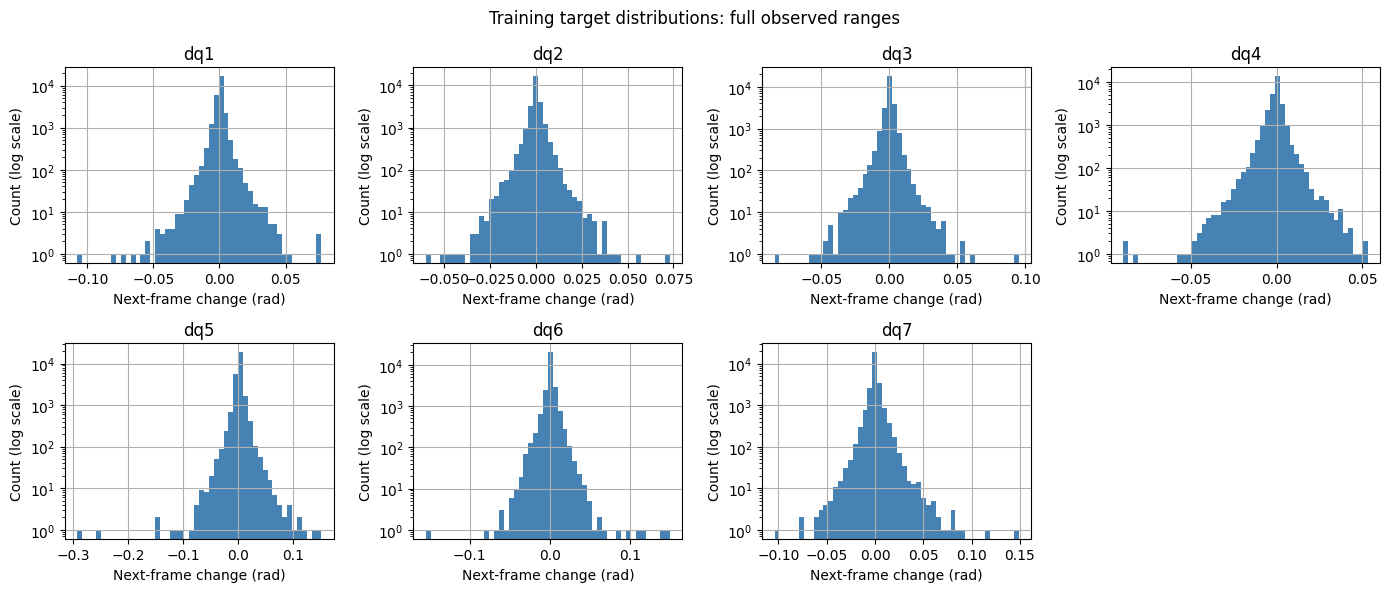

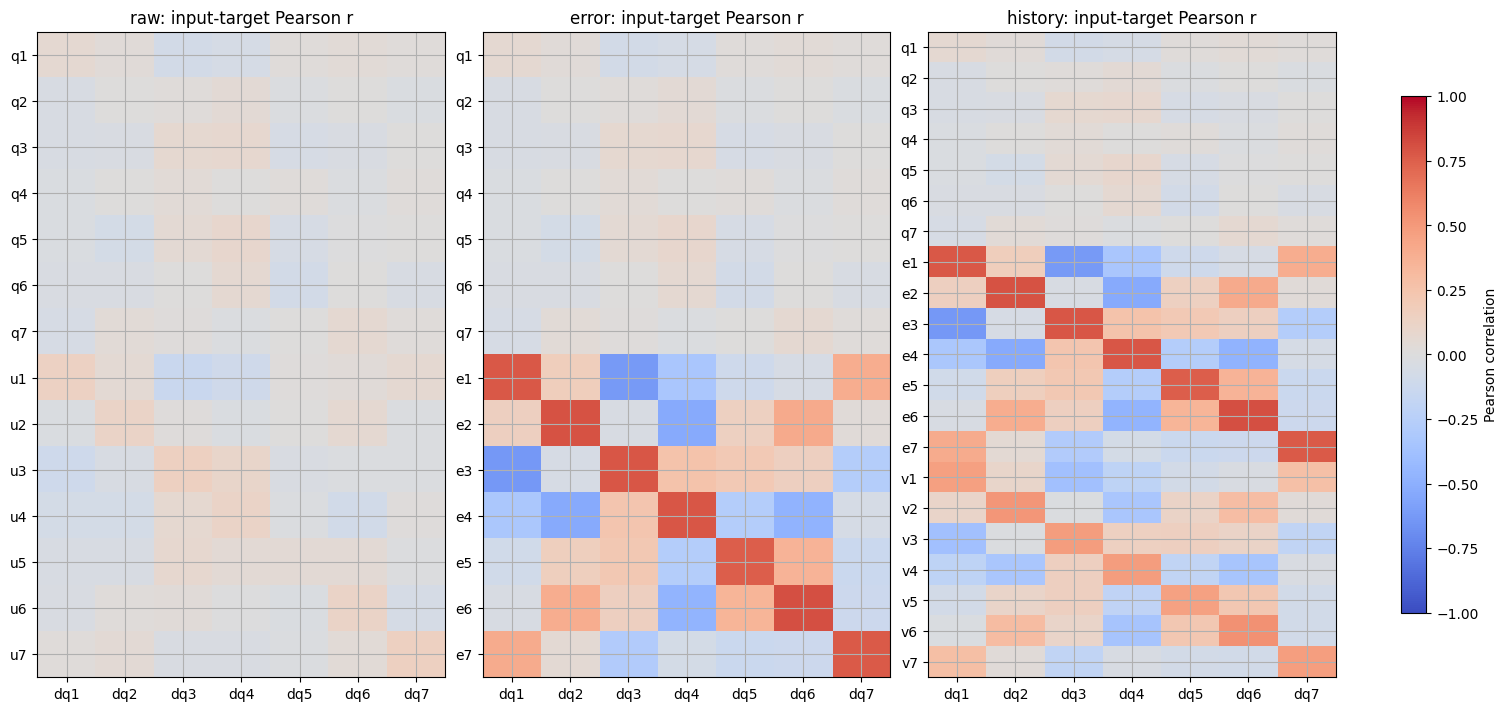

Strongest absolute input-target correlation in each representation


,representation,input,target,Pearson_r
0,raw,u7,dq7,1.482572e-01
1,error,e6,dq6,8.051649e-01
2,history,e6,dq6,8.051649e-01


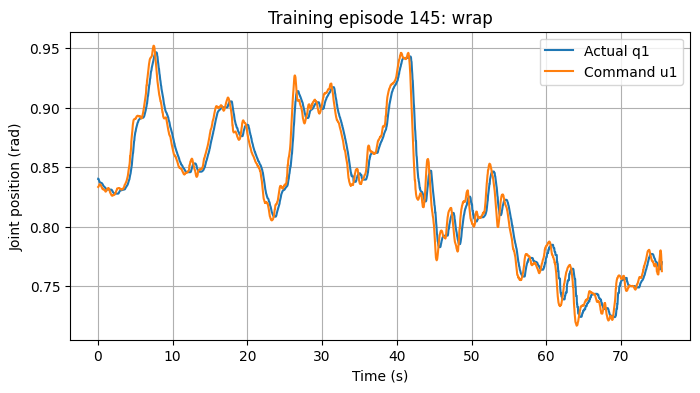

Target spread: dq5 has the largest standard deviation (8.103993e-03 rad); dq2 has the smallest (3.881598e-03 rad).
7 of 7 target medians are exactly zero.
The histogram count axes are logarithmic so rare large changes remain visible.
Different target spreads affect raw-unit MSE and motivate the Q7 loss comparison.
raw: strongest pair u7 / dq7, r = +0.148.
error: strongest pair e6 / dq6, r = +0.805.
history: strongest pair e6 / dq6, r = +0.805.
A correlation measures a single linear association, not causal influence
or achieved prediction accuracy. The comparisons in Q7 evaluate whether the
engineered features improve generalization. Tracking error re-expresses q and u;
past velocity adds information from the previous frame.

In illustrated training episode 145, mean absolute q1 tracking error is 8.604378e-03 rad.
The trajectory plot compares a command with the actual position. This describes tracking behaviour but does not identify the physical cause of any gap.


In [ ]:
# Q2 - Dataset, exploration, preprocessing and grouped 60/20/20 split

# Run Exercise 3 Q1 before this cell.
print('Dataset: T-Rex robot manipulation dataset')
print(f'Source: https://huggingface.co/datasets/{REPO}')
print('Pinned dataset revision:', REVISION)
print('This experiment uses joint-state and command records from two frame files.')
print('The dataset records 58 positions and 58 commanded positions at 30 Hz.')
print('The first seven entries describe the left arm; images and tactile inputs '
      'are outside this experiment.')

# Pinned files: approximately 152 MB total; no videos or LeRobot installation.
FILES = {
    'episodes_preview.parquet': 230648,
    'data/chunk-000/file-000.parquet': 80118634,
    'data/chunk-000/file-001.parquet': 71797668,
}

def download_file(name, expected_size):
    destination = DATA_DIR / name
    destination.parent.mkdir(parents=True, exist_ok=True)
    if destination.exists() and destination.stat().st_size == expected_size:
        return destination
    url = f'https://huggingface.co/datasets/{REPO}/resolve/{REVISION}/{name}'
    temporary = destination.with_suffix('.part')
    for attempt in range(1, 4):
        try:
            print(f'Downloading: {name} (attempt {attempt}/3)', flush=True)
            with requests.get(url, stream=True, timeout=(30, 180)) as response:
                response.raise_for_status()
                with temporary.open('wb') as handle:
                    for block in response.iter_content(1024 * 1024):
                        if block:
                            handle.write(block)
            if temporary.stat().st_size != expected_size:
                raise RuntimeError('Downloaded file size does not match the pinned file.')
            temporary.replace(destination)
            return destination
        except (requests.RequestException, OSError, RuntimeError):
            if attempt == 3:
                raise
            time.sleep(2 * attempt)

paths = {name: download_file(name, size) for name, size in FILES.items()}
episodes = pd.read_parquet(paths['episodes_preview.parquet'])
columns = ['observation.state', 'action', 'episode_index', 'frame_index', 'timestamp']
frames = pd.concat([pd.read_parquet(paths[name], columns=columns)
                    for name in FILES if name.startswith('data/')], ignore_index=True)
assert not frames.duplicated(['episode_index', 'frame_index']).any()
counts = frames.groupby('episode_index').size()
complete = episodes[episodes.episode_index.map(counts).eq(episodes.length)].copy()
caption = complete.caption.fillna('').str.lower()
# A transparent text filter; it is not a ground-truth active-hand annotation.
eligible = complete[caption.str.contains('left hand') &
                    ~caption.str.contains('right hand|both hands')]
if len(eligible) < N_EPISODES or N_EPISODES % 5:
    raise ValueError('N_EPISODES must be a multiple of 5 and <= eligible count.')
ids = np.random.default_rng(SEED).permutation(sorted(eligible.episode_index))[:N_EPISODES]
split_ids = dict(zip(['train', 'val', 'test'],
                    np.split(ids, [3*N_EPISODES//5, 4*N_EPISODES//5])))
metadata = episodes.set_index('episode_index')

# Every representation uses exactly the same current-frame rows and targets.
# t-1 is an input history frame; t+1 is used ONLY to construct the target.
RAW_NAMES = {
    'raw': [f'q{j}' for j in range(1, 8)] + [f'u{j}' for j in range(1, 8)],
    'error': [f'q{j}' for j in range(1, 8)] + [f'e{j}' for j in range(1, 8)],
    'history': ([f'q{j}' for j in range(1, 8)] +
                [f'e{j}' for j in range(1, 8)] + [f'v{j}' for j in range(1, 8)]),
}

# A sample predicts a change in actual joint position, using only current/past inputs.
feature_definitions = pd.DataFrame([
    ['q1-q7', 'Actual left-arm positions at t', 7, 'rad', 'raw, error, history'],
    ['u1-u7', 'Commanded target positions at t', 7, 'rad', 'raw'],
    ['e1-e7', 'Tracking error: u(t) - q(t)', 7, 'rad', 'error, history'],
    ['v1-v7', 'Past velocity: (q(t) - q(t-1)) / dt', 7, 'rad/s', 'history'],
    ['dq1-dq7', 'Target: q(t+1) - q(t)', 7, 'rad', 'target for all models'],
], columns=['variables', 'meaning', 'dimensions', 'unit', 'used_in'])
print('Input features and target definition')
display(feature_definitions)
print('raw: [q(t), u(t)] -> 14 inputs; error: [q(t), e(t)] -> 14 inputs.')
print('history: [q(t), e(t), v(t)] -> 21 inputs; each target has 7 outputs.')
print('The target is the next-frame actual displacement, not the command or velocity.')
print('q(t+1) is used only for the target. Previous velocity uses t-1 and t.')
feature_definitions.to_csv(OUTPUT_DIR / 'q2_feature_definitions.csv', index=False)

X_parts = {name: [] for name in RAW_NAMES}
y_parts, row_parts = [], []
dropped_triplets, candidate_triplets = 0, 0
gap_triplets, nonfinite_triplets = 0, 0
for ep, group in frames[frames.episode_index.isin(ids)].groupby('episode_index'):
    group = group.sort_values('frame_index')
    state = np.stack(group['observation.state']).astype('float32')
    action = np.stack(group['action']).astype('float32')
    assert state.shape[1] == action.shape[1] == 58
    if len(group) < 3:
        continue
    dt = np.diff(group.timestamp.to_numpy(dtype='float64'))
    consecutive = (np.diff(group.frame_index.to_numpy()) == 1)
    consecutive &= np.isclose(dt, 1/30, atol=1e-4, rtol=0)
    q, u = state[1:-1, :7], action[1:-1, :7]
    with np.errstate(divide='ignore', invalid='ignore'):
        velocity = (q - state[:-2, :7]) / dt[:-1, None]
    X_ep = {
        'raw': np.concatenate([q, u], axis=1),
        'error': np.concatenate([q, u-q], axis=1),
        'history': np.concatenate([q, u-q, velocity], axis=1),
    }
    y_ep = state[2:, :7] - q
    valid = consecutive[:-1] & consecutive[1:]
    valid &= np.isfinite(y_ep).all(axis=1)
    for name in X_ep:
        valid &= np.isfinite(X_ep[name]).all(axis=1)
    gap_triplets += int((~(consecutive[:-1] & consecutive[1:])).sum())
    finite_values = np.isfinite(y_ep).all(axis=1)
    for values in X_ep.values():
        finite_values &= np.isfinite(values).all(axis=1)
    nonfinite_triplets += int((~finite_values).sum())
    candidate_triplets += len(valid)
    dropped_triplets += int((~valid).sum())
    for name in X_parts:
        X_parts[name].append(X_ep[name][valid].astype('float32'))
    y_parts.append(y_ep[valid])
    row_parts.append(group.iloc[1:-1][['episode_index', 'frame_index', 'timestamp']]
                    .iloc[np.flatnonzero(valid)])

X = {name: np.concatenate(parts) for name, parts in X_parts.items()}
y = np.concatenate(y_parts)
sample_info = pd.concat(row_parts, ignore_index=True)
masks = {s: sample_info.episode_index.isin(v).to_numpy() for s, v in split_ids.items()}
assert all(set(split_ids[a]).isdisjoint(split_ids[b])
           for a, b in [('train', 'val'), ('train', 'test'), ('val', 'test')])
assert set(sample_info.episode_index) == set(ids)
assert all(m.any() for m in masks.values())
x_scalers = {name: StandardScaler().fit(values[masks['train']])
             for name, values in X.items()}
y_scaler = StandardScaler().fit(y[masks['train']])
data = {}
for split, mask in masks.items():
    data[split] = {
        'X_raw': {name: values[mask] for name, values in X.items()},
        'X': {name: torch.from_numpy(x_scalers[name].transform(values[mask]).astype('float32'))
              for name, values in X.items()},
        'y_raw': y[mask],
        'y': torch.from_numpy(y_scaler.transform(y[mask]).astype('float32')),
        'info': sample_info.loc[mask].reset_index(drop=True),
    }

# Diagnostic categories may overlap; the original valid mask decides removal.
preprocessing_audit = pd.DataFrame([
    ['Candidate frame triplets before filtering', candidate_triplets],
    ['Triplets with a frame/time gap', gap_triplets],
    ['Triplets with nonfinite predictors or targets', nonfinite_triplets],
    ['Triplets removed for either reason', dropped_triplets],
    ['Valid triplets retained', len(y)],
], columns=['check', 'count'])
print('Preprocessing checks on the selected trajectories')
display(preprocessing_audit)
print('Gap and nonfinite counts may overlap. Retained + removed equals candidates.')
print(f'Complete trajectories with missing captions: {int(complete.caption.isna().sum())}. '
      'Missing captions become empty strings for the text filter.')
print('''Preprocessing:
1. Check duplicate episode/frame IDs and use complete trajectories.
2. Sort frames within each trajectory and construct t-1, t, t+1 windows.
3. Remove a window if a needed value is NaN/infinite or its frame/time spacing
   is invalid. Missing numeric values are not imputed across temporal gaps.
4. Standardize each input column using z = (x - training_mean) / training_std.
   StandardScaler uses population standard deviation. The descriptive tables
   below use pandas sample standard deviation, so small differences are expected.
5. Apply each fitted training scaler to validation and test data. Standardize
   targets separately and invert that transform when computing MSE in rad^2.
6. All predictors are numeric. Captions select trajectories and motor_primitive
   describes task coverage; neither is supplied as an input. One-hot encoding
   is therefore unnecessary. Missing task metadata is labelled Unknown for counts.
Large but finite motions remain in the data. Their prediction errors are
examined in Q8 rather than removing them during preprocessing.
''')
preprocessing_audit.to_csv(OUTPUT_DIR / 'q2_preprocessing_audit.csv', index=False)

motion_threshold = float(np.quantile(np.linalg.norm(data['train']['y_raw'], axis=1), 0.90))
split_summary = pd.DataFrame([
    {'split': s, 'episodes': len(split_ids[s]),
     'episode_%': 100*len(split_ids[s])/N_EPISODES,
     'samples': len(data[s]['y_raw']), 'sample_%': 100*len(data[s]['y_raw'])/len(y)}
    for s in data
])
print('Complete episodes:', len(complete), '| eligible:', len(eligible))
print('Candidate history/target triplets:', candidate_triplets)
print('Dropped invalid/nonconsecutive triplets:', dropped_triplets)
display(split_summary)
print('''60/20/20 is by whole episode (36/12/12); sample percentages differ
because trajectories have different lengths. Whole-episode splitting prevents
adjacent frames from the same trajectory appearing in different partitions.
All predictors use the same valid rows: both a preceding frame and next-frame
target are required. The first frame of each episode is therefore omitted.
Invalid/nonfinite or nonconsecutive triplets are removed, not filled across gaps.
Scalers use training data only. No categorical input encoding is needed.
The error features u-q re-express existing information; past velocity adds history.
The dataset card identifies positions/targets and left-arm joints in [:7].
Subset limitation: two files and a caption filter, not all T-Rex trajectories.
These test episodes were inspected in the earlier exploratory analysis. Model
selection below uses validation only; new, untouched episodes would be needed
for a stronger independent confirmation of the revised modelling choices.
''')
print(f'Training-defined large-motion threshold (90th percentile): {motion_threshold:.6e} rad')
manifest = {
    'repo': REPO, 'revision': REVISION,
    'split_episode_ids': {s: [int(i) for i in v] for s, v in split_ids.items()},
    'features': RAW_NAMES,
    'target': 'q(t+1)-q(t), left-arm joints 1-7, radians',
    'alignment': 'same valid consecutive t-1,t,t+1 triplets for every predictor',
    'large_motion_threshold': motion_threshold,
}
(OUTPUT_DIR / 'data_split.json').write_text(json.dumps(manifest, indent=2), encoding='utf-8')
split_summary.to_csv(OUTPUT_DIR / 'q2_split_summary.csv', index=False)

# The evaluation unit is a whole trajectory; the metric still averages frames.
print(f'Dataset choice: {N_EPISODES} complete, caption-filtered trajectories, '
      f'including {len(split_ids["train"])} training trajectories.')
print("""Why this split: the intended evaluation is prediction on unseen trajectories
from this selected task subset. Adjacent frames and overlapping history windows
share information, so random frame splitting could produce optimistic results.
Keeping every episode in one partition avoids this direct temporal overlap.
It does not guarantee independence across objects or tasks, or unseen-task skill.

Why 60: this is a bounded subset for repeated experiments with a modest MLP and
about 152 MB of downloaded data. Feasibility is a practical reason, not evidence
that 60 trajectories are sufficient. Thousands of correlated frames do not equal
thousands of independent trajectories. Q7 varies the training subset through
9/18/27/36 trajectories while keeping the 12 validation and 12 test episodes fixed.
The learning curve investigates training-data benefit within this subset; it
cannot establish that the whole 60-episode subset represents all T-Rex tasks.

I prioritize intact trajectories and disclose the resulting frame proportions,
rather than claim exact 60/20/20 by samples. All model comparisons use the same
valid sample rows. Frame-averaged MSE gives longer trajectories more weight;
future work can also report equal-weight episode errors and uncertainty.
""")

# Task metadata describes partition coverage; it is not supplied as model input.
task_distribution = pd.DataFrame({
    s: metadata.loc[episode_ids, 'motor_primitive'].fillna('Unknown').value_counts()
    for s, episode_ids in split_ids.items()
}).fillna(0).astype(int).reindex(columns=list(data)).sort_index()
print('Task-type coverage: counts of complete episodes in each partition')
display(task_distribution)
for split in ['val', 'test']:
    missing_from_train = task_distribution.index[
        (task_distribution[split] > 0) & (task_distribution['train'] == 0)]
    print(f'{split}: task types present but absent from training: '
          f'{", ".join(missing_from_train) if len(missing_from_train) else "none"}.')
print('Task frequencies and coverage differ across partitions. These are limitations '
      'to discuss, not reasons to search for a more favourable test split.')
task_distribution.to_csv(OUTPUT_DIR / 'q2_task_distribution.csv')

# EDA uses training data only. Summarize each distinct input once.
feature_names = RAW_NAMES['raw']
target_names = [f'dq{j}' for j in range(1, 8)]
eda = pd.DataFrame(np.c_[data['train']['X_raw']['raw'], data['train']['y_raw']],
                   columns=feature_names + target_names)
input_names = feature_names + RAW_NAMES['history'][7:]
eda_inputs = pd.DataFrame(
    np.c_[data['train']['X_raw']['raw'], data['train']['X_raw']['history'][:, 7:]],
    columns=input_names)
input_summary = eda_inputs.describe().T
input_summary.insert(0, 'unit',
                     ['rad/s' if name.startswith('v') else 'rad' for name in input_names])
target_summary = eda[target_names].describe().T
print('Training input statistics: q, u, e and v (28 distinct variables)')
display(input_summary)
print('Training target statistics: seven next-frame changes in radians')
display(target_summary)
input_summary.to_csv(OUTPUT_DIR / 'q2_input_statistics.csv')
target_summary.to_csv(OUTPUT_DIR / 'q2_target_statistics.csv')

# Separate histograms show each joint's full observed range, including rare changes.
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for axis, name in zip(axes.flat, target_names):
    axis.hist(eda[name], bins=50, color='steelblue')
    axis.set(title=name, xlabel='Next-frame change (rad)',
             ylabel='Count (log scale)', yscale='log')
axes.flat[-1].axis('off')
fig.suptitle('Training target distributions: full observed ranges')
plt.tight_layout(); plt.show()

# Use the same correlation scale and targets for all three input representations.
correlations = {}
for name, names in RAW_NAMES.items():
    combined = pd.DataFrame(np.c_[data['train']['X_raw'][name], data['train']['y_raw']],
                            columns=names + target_names)
    correlations[name] = combined.corr().loc[names, target_names]
    correlations[name].to_csv(OUTPUT_DIR / f'q2_{name}_target_correlations.csv')
corr = correlations['raw']
fig, axes = plt.subplots(1, 3, figsize=(15, 7), layout='constrained')
for axis, (name, values) in zip(axes, correlations.items()):
    image = axis.imshow(values, vmin=-1, vmax=1, cmap='coolwarm', aspect='auto')
    axis.set_xticks(range(7), target_names)
    axis.set_yticks(range(len(values)), values.index)
    axis.set_title(f'{name}: input-target Pearson r')
fig.colorbar(image, ax=axes, label='Pearson correlation', shrink=0.8)
plt.show()

strongest_correlations = []
for name, values in correlations.items():
    pair = values.abs().stack().idxmax()
    strongest_correlations.append({
        'representation': name, 'input': pair[0], 'target': pair[1],
        'Pearson_r': float(values.loc[pair]),
    })
print('Strongest absolute input-target correlation in each representation')
display(pd.DataFrame(strongest_correlations))

# This trajectory plot illustrates state/command behaviour within one training episode.
ep = int(split_ids['train'][0])
mask = data['train']['info'].episode_index.eq(ep).to_numpy()
plt.plot(data['train']['info'].loc[mask, 'timestamp'],
         data['train']['X_raw']['raw'][mask, 0], label='Actual q1')
plt.plot(data['train']['info'].loc[mask, 'timestamp'],
         data['train']['X_raw']['raw'][mask, 7], label='Command u1')
plt.title(f'Training episode {ep}: {metadata.loc[ep, "motor_primitive"]}')
plt.xlabel('Time (s)'); plt.ylabel('Joint position (rad)'); plt.legend(); plt.show()

target_std = target_summary['std']
largest_target, smallest_target = target_std.idxmax(), target_std.idxmin()
print(f'Target spread: {largest_target} has the largest standard deviation '
      f'({target_std[largest_target]:.6e} rad); {smallest_target} has the smallest '
      f'({target_std[smallest_target]:.6e} rad).')
print(f'{int(target_summary["50%"].eq(0).sum())} of 7 target medians are exactly zero.')
print('The histogram count axes are logarithmic so rare large changes remain visible.')
print('Different target spreads affect raw-unit MSE and motivate the Q7 loss comparison.')
for result in strongest_correlations:
    print(f'{result["representation"]}: strongest pair {result["input"]} / '
          f'{result["target"]}, r = {result["Pearson_r"]:+.3f}.')
print('''A correlation measures a single linear association, not causal influence
or achieved prediction accuracy. The comparisons in Q7 evaluate whether the
engineered features improve generalization. Tracking error re-expresses q and u;
past velocity adds information from the previous frame.
''')
q1_error = data['train']['X_raw']['error'][mask, 7]
print(f'In illustrated training episode {ep}, mean absolute q1 tracking error '
      f'is {np.mean(np.abs(q1_error)):.6e} rad.')
print('The trajectory plot compares a command with the actual position. This '
      'describes tracking behaviour but does not identify the physical cause of any gap.')

del frames, X_parts, y_parts, row_parts


# Question 3

In [ ]:
# Q3 - Model design: a simple feedforward MLP and controlled extensions
ACTIVATIONS = {
    'relu': nn.ReLU, 'sigmoid': nn.Sigmoid, 'tanh': nn.Tanh,
    'leaky_relu': lambda: nn.LeakyReLU(0.1), 'gelu': nn.GELU,
}

class MLP(nn.Module):
    def __init__(self, input_dim=14, hidden=(64, 32), output_dim=7, activation='relu'):
        super().__init__()
        layers, previous = [], input_dim
        for width in hidden:
            layers += [nn.Linear(previous, width), ACTIVATIONS[activation]()]
            previous = width
        layers.append(nn.Linear(previous, output_dim))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

set_seed()
model = MLP().to(DEVICE)
print(model)
print('Trainable parameters:', sum(p.numel() for p in model.parameters()))
assert model(data['train']['X']['raw'][:5].to(DEVICE)).shape == (5, 7)
loss_weights = torch.tensor(y_scaler.scale_**2, dtype=torch.float32, device=DEVICE)
loss_weights = loss_weights / loss_weights.mean()
display(pd.DataFrame({'joint': range(1, 8), 'target_std_rad': y_scaler.scale_,
                      'raw_MSE_weight': loss_weights.cpu().numpy()}))
print('''Architecture: 14 -> 64 (ReLU) -> 32 (ReLU) -> 7 (linear).
The history version changes only the input width to 21 (3,719 parameters).
Two modest hidden layers model nonlinear state-command interactions without
requiring a recurrent network. ReLU is simple; linear outputs allow both signs.
Two layers are an initial design choice, not an assumed optimum. Q7 compares
one, two and three hidden layers at nearly equal parameter counts, and selects
the final standalone architecture using validation results only.
Original loss: mean((pred_z - target_z)^2), with standardized targets.
Aligned loss: mean(w * (pred_z - target_z)^2), w = target_std^2 / mean(target_std^2).
The aligned loss is raw-unit MSE divided by a constant estimated on training data.
This tests the evaluation objective; the original standardized loss is not a bug.
All reported curves and metrics are evaluated in original units (rad^2).
The optional hybrid freezes Ridge and learns a residual with the same MLP.
Its prediction is inverse_scale(Ridge_z + gamma * MLP_residual_z).
The independent MLP remains the main assignment model, even if Ridge is better.
''')


MLP(
  (net): Sequential(
    (0): Linear(in_features=14, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=7, bias=True)
  )
)
Trainable parameters: 3271


,joint,target_std_rad,raw_MSE_weight
0,1,4.345427e-03,6.074491e-01
1,2,3.881526e-03,4.846742e-01
2,3,4.223633e-03,5.738748e-01
3,4,5.156728e-03,8.554476e-01
4,5,8.103935e-03,2.112695e+00
5,6,6.131037e-03,1.209241e+00
6,7,5.996154e-03,1.156619e+00


Architecture: 14 -> 64 (ReLU) -> 32 (ReLU) -> 7 (linear).
The history version changes only the input width to 21 (3,719 parameters).
Two modest hidden layers model nonlinear state-command interactions without
requiring a recurrent network. ReLU is simple; linear outputs allow both signs.
Two layers are an initial design choice, not an assumed optimum. Q7 compares
one, two and three hidden layers at nearly equal parameter counts, and selects
the final standalone architecture using validation results only.
Original loss: mean((pred_z - target_z)^2), with standardized targets.
Aligned loss: mean(w * (pred_z - target_z)^2), w = target_std^2 / mean(target_std^2).
The aligned loss is raw-unit MSE divided by a constant estimated on training data.
This tests the evaluation objective; the original standardized loss is not a bug.
All reported curves and metrics are evaluated in original units (rad^2).
The optional hybrid freezes Ridge and learns a residual with the same MLP.
Its prediction is in

# Question 4

MLP, raw, hidden=(64, 32), standardized, lr=0.001, seed=42, epoch=01, train=2.761e-05, val=2.829e-05
MLP, raw, hidden=(64, 32), standardized, lr=0.001, seed=42, epoch=40, train=1.263e-05, val=1.451e-05


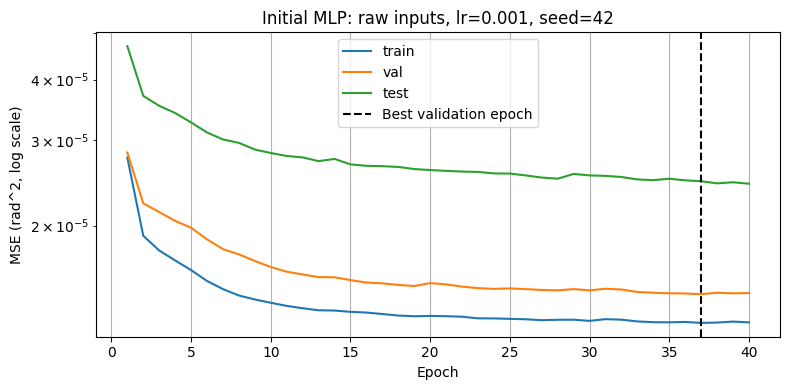

Restored validation-selected epoch: 37
Fixed budget: 40 epochs, Adam, batch size 256; no actual early stopping.


In [ ]:
# Q4 - Training and validation; test curves are required by the assignment
def network_output(model, X_tensor):
    model.eval()
    with torch.no_grad():
        outputs = [model(batch.to(DEVICE)).cpu().numpy()
                   for batch in X_tensor.split(4096)]
    return np.concatenate(outputs)

def predict_run(run, split, gamma=None):
    run_data = run['data']
    X_tensor = run_data[split]['X'][run['feature']]
    prediction_z = network_output(run['model'], X_tensor)
    if run['ridge'] is not None:
        strength = run['gamma'] if gamma is None else gamma
        prediction_z = run['ridge'].predict(X_tensor.numpy()) + strength * prediction_z
    return run['y_scaler'].inverse_transform(prediction_z)

def train_regressor(feature='raw', loss_name='standardized', base_lr=0.001,
                    epochs=EPOCHS, seed=SEED, ridge=None, hidden=(64, 32),
                    dataset=None, target_scaler=None,
                    eval_splits=('train', 'val', 'test'), store_checkpoints=False):
    set_seed(seed)
    run_data = data if dataset is None else dataset
    run_scaler = y_scaler if target_scaler is None else target_scaler
    assert 'train' in eval_splits and 'val' in eval_splits
    assert all(split in run_data for split in eval_splits)
    model = MLP(input_dim=run_data['train']['X'][feature].shape[1], hidden=hidden).to(DEVICE)
    train_target = run_data['train']['y'].clone()
    if ridge is not None:
        # Subtract in standardized coordinates; do not subtract y_mean twice.
        ridge_z = ridge.predict(run_data['train']['X'][feature].numpy())
        train_target -= torch.from_numpy(ridge_z.astype('float32'))
        nn.init.zeros_(model.net[-1].weight)
        nn.init.zeros_(model.net[-1].bias)
    loader = DataLoader(TensorDataset(run_data['train']['X'][feature], train_target),
                        batch_size=BATCH_SIZE, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))
    optimizer = torch.optim.Adam(model.parameters(), lr=base_lr)
    local_weights = torch.tensor(run_scaler.scale_**2, dtype=torch.float32, device=DEVICE)
    local_weights = local_weights / local_weights.mean()
    weights = local_weights if loss_name == 'aligned' else torch.ones_like(local_weights)
    run = {'model': model, 'feature': feature, 'loss_name': loss_name,
           'lr': base_lr, 'seed': seed, 'ridge': ridge, 'gamma': 1.0,
           'hidden': tuple(hidden), 'data': run_data, 'y_scaler': run_scaler,
           'checkpoints': []}
    history, best_val, best_state, best_epoch = [], float('inf'), None, None
    started = time.perf_counter()
    training_seconds, eval_seconds = 0.0, 0.0
    for epoch in range(1, epochs + 1):
        if DEVICE.type == 'cuda':
            torch.cuda.synchronize()
        train_started = time.perf_counter()
        model.train()
        for xb, yb in loader:
            optimizer.zero_grad(set_to_none=True)
            loss = (weights * (model(xb.to(DEVICE)) - yb.to(DEVICE)).square()).mean()
            if not torch.isfinite(loss):
                raise RuntimeError(f'Nonfinite loss: feature={feature}, lr={base_lr}.')
            loss.backward()
            optimizer.step()
        if DEVICE.type == 'cuda':
            torch.cuda.synchronize()
        training_seconds += time.perf_counter() - train_started
        eval_started = time.perf_counter()
        metrics = {s: mean_squared_error(run_data[s]['y_raw'], predict_run(run, s))
                   for s in eval_splits}
        eval_seconds += time.perf_counter() - eval_started
        history.append({'epoch': epoch, **metrics})
        # Test is recorded for the required plot, never for selection or gradients.
        if metrics['val'] < best_val:
            best_val, best_epoch = metrics['val'], epoch
            best_state = copy.deepcopy(model.state_dict())
        if store_checkpoints:
            run['checkpoints'].append({k: v.detach().cpu().clone()
                                       for k, v in model.state_dict().items()})
        if epoch == 1 or epoch == epochs:
            kind = 'hybrid' if ridge is not None else 'MLP'
            print(f'{kind}, {feature}, hidden={hidden}, {loss_name}, lr={base_lr:g}, seed={seed}, '
                  f'epoch={epoch:02d}, train={metrics["train"]:.3e}, '
                  f'val={metrics["val"]:.3e}', flush=True)
    model.load_state_dict(best_state)
    run.update(history=pd.DataFrame(history), best_epoch=best_epoch,
               seconds=time.perf_counter()-started, training_seconds=training_seconds,
               eval_seconds=eval_seconds)
    return run

def plot_learning_curves(run, title):
    run['history'].plot(x='epoch', y=['train', 'val', 'test'], logy=True)
    plt.axvline(run['best_epoch'], color='black', linestyle='--',
                label='Best validation epoch')
    plt.title(title)
    plt.xlabel('Epoch'); plt.ylabel('MSE (rad^2, log scale)')
    plt.legend(); plt.tight_layout(); plt.show()

baseline = train_regressor()
plot_learning_curves(baseline, 'Initial MLP: raw inputs, lr=0.001, seed=42')
print('Restored validation-selected epoch:', baseline['best_epoch'])
print('Fixed budget: 40 epochs, Adam, batch size 256; no actual early stopping.')
baseline['history'].to_csv(OUTPUT_DIR / 'q4_initial_loss_history.csv', index=False)


# Question 5

,Initial MLP,Persistence,Ridge raw
train,1.259531e-05,3.132180e-05,1.232328e-05
val,1.443337e-05,3.116626e-05,1.348322e-05
test,2.468344e-05,5.148384e-05,2.219454e-05


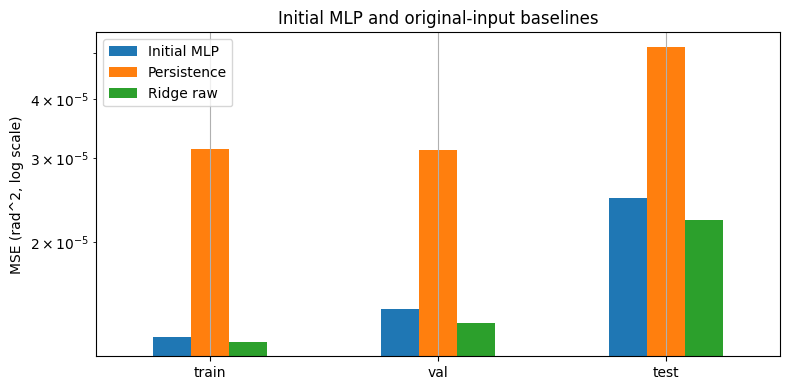

train: initial MLP improves over persistence by 59.79%; its MSE is higher than Ridge.
val: initial MLP improves over persistence by 53.69%; its MSE is higher than Ridge.
test: initial MLP improves over persistence by 52.06%; its MSE is higher than Ridge.
Zero predicted change is persistence: q(t+1)=q(t).
Ridge is a regularized linear reference, not a neural-network result.
Negative improvement means worse performance. A neural model need not win.
This table describes the INITIAL model. Q7 reports the selected FINAL MLP,
including three-set metrics, joint errors, seed variability and loss curves.



In [ ]:
# Q5 - Regression evaluation and meaningful baselines
# Fit each Ridge on matching inputs, with fixed alpha=1.0 (not tuned on test).
ridge_models = {feature: Ridge(alpha=1.0).fit(data['train']['X'][feature].numpy(),
                                            data['train']['y'].numpy())
                for feature in RAW_NAMES}
ridge_predictions = {
    feature: {s: y_scaler.inverse_transform(ridge.predict(data[s]['X'][feature].numpy()))
              for s in data}
    for feature, ridge in ridge_models.items()
}
baseline_predictions = {s: predict_run(baseline, s) for s in data}
persistence_predictions = {s: np.zeros_like(data[s]['y_raw']) for s in data}

def evaluate_predictions(predictors):
    return pd.DataFrame({name: {s: mean_squared_error(data[s]['y_raw'], values[s])
                               for s in data}
                         for name, values in predictors.items()}).reindex(list(data))

initial_metrics = evaluate_predictions({
    'Initial MLP': baseline_predictions,
    'Persistence': persistence_predictions,
    'Ridge raw': ridge_predictions['raw'],
})
display(initial_metrics)
initial_metrics.plot.bar(rot=0, logy=True)
plt.ylabel('MSE (rad^2, log scale)'); plt.title('Initial MLP and original-input baselines')
plt.tight_layout(); plt.show()
for split in data:
    improvement = 100*(1-initial_metrics.loc[split, 'Initial MLP'] /
                      initial_metrics.loc[split, 'Persistence'])
    comparison = 'lower' if initial_metrics.loc[split, 'Initial MLP'] < initial_metrics.loc[split, 'Ridge raw'] else 'higher'
    print(f'{split}: initial MLP improves over persistence by {improvement:.2f}%; '
          f'its MSE is {comparison} than Ridge.')
print('''Zero predicted change is persistence: q(t+1)=q(t).
Ridge is a regularized linear reference, not a neural-network result.
Negative improvement means worse performance. A neural model need not win.
This table describes the INITIAL model. Q7 reports the selected FINAL MLP,
including three-set metrics, joint errors, seed variability and loss curves.
''')
initial_metrics.to_csv(OUTPUT_DIR / 'q5_initial_metrics.csv')


# Question 6

In [ ]:
# Q6 - Overfitting and underfitting analysis using actual curves and metrics
def discuss_generalization(run, predictions, label):
    history = run['history']
    first, last = history.iloc[0], history.iloc[-1]
    selected = {s: mean_squared_error(data[s]['y_raw'], predictions[s]) for s in data}
    ratio = selected['val'] / max(selected['train'], 1e-15)
    rebound = 100 * (last['val'] / max(history.val.min(), 1e-15) - 1)
    print(f'{label}: best epoch={run["best_epoch"]}, validation/train ratio={ratio:.3f}')
    print(f'Training MSE, first -> last: {first["train"]:.6e} -> {last["train"]:.6e}')
    print(f'Validation MSE, best -> last: {history.val.min():.6e} -> {last["val"]:.6e}')
    print(f'Selected train/val/test MSE: {selected["train"]:.6e} / '
          f'{selected["val"]:.6e} / {selected["test"]:.6e}')
    print(f'End-of-training validation rebound above the minimum: {rebound:.2f}%.')
    if last['train'] < first['train'] and rebound > 10:
        print('Training improves overall while validation ends appreciably above its '
              'minimum. This pattern is consistent with late overfitting.')
    elif last['train'] < first['train'] and rebound > 0:
        print('There is a small late validation rebound while training improves overall. '
              'This gives limited evidence of late overfitting; the endpoints alone '
              'do not establish a persistent divergence of the curves.')
    else:
        print('These endpoints do not show training improvement accompanied by a '
              'late validation rebound. Inspect the full curves as well.')
    persistence_gains = {}
    for split in ['train', 'val']:
        reference = mean_squared_error(data[split]['y_raw'], persistence_predictions[split])
        persistence_gains[split] = 100 * (1 - selected[split] / max(reference, 1e-15))
    print(f'MSE reduction versus persistence: train={persistence_gains["train"]:.2f}%, '
          f'validation={persistence_gains["val"]:.2f}%.')
    if min(persistence_gains.values()) > 0:
        print('The model learns useful signal on both training and validation data. '
              'The current evidence does not establish severe underfitting. '
              'Beating persistence alone cannot exclude remaining underfitting.')
    else:
        print('The model does not beat persistence on both partitions. Poor fit may '
              'reflect capacity, optimization or insufficient inputs; these results '
              'alone cannot distinguish those causes.')
    print('''A split gap alone does not prove overfitting: episodes differ in task,
objects and motion. A lower Ridge error also cannot by itself identify underfitting.
Training-fit, optimization and controlled-capacity comparisons inform that diagnosis.
The 10% rebound distinction is descriptive, not a statistical significance test.
Possible remedies include more independent trajectories, weight decay, dropout,
a smaller network, and validation-based early stopping. I restore the best
validation checkpoint after 40 epochs; training still runs for the full budget.
''')

discuss_generalization(baseline, baseline_predictions, 'Initial MLP')
print('The selected final MLP is assessed with this same function at the end of Q7.')


Initial MLP: best epoch=37, validation/train ratio=1.146
Training MSE, first -> last: 2.760641e-05 -> 1.262509e-05
Validation MSE, best -> last: 1.443337e-05 -> 1.451160e-05
Selected train/val/test MSE: 1.259531e-05 / 1.443337e-05 / 2.468344e-05
End-of-training validation rebound above the minimum: 0.54%.
There is a small late validation rebound while training improves overall. This gives limited evidence of late overfitting; the endpoints alone do not establish a persistent divergence of the curves.
MSE reduction versus persistence: train=59.79%, validation=53.69%.
The model learns useful signal on both training and validation data. The current evidence does not establish severe underfitting. Beating persistence alone cannot exclude remaining underfitting.
A split gap alone does not prove overfitting: episodes differ in task,
objects and motion. A lower Ridge error also cannot by itself identify underfitting.
Training-fit, optimization and controlled-capacity comparisons inform that d

# Question 7

MLP, raw, hidden=(64, 32), standardized, lr=0.1, seed=42, epoch=01, train=3.057e-05, val=3.066e-05
MLP, raw, hidden=(64, 32), standardized, lr=0.1, seed=42, epoch=40, train=2.570e-05, val=2.649e-05
MLP, raw, hidden=(64, 32), standardized, lr=0.01, seed=42, epoch=01, train=1.715e-05, val=2.072e-05
MLP, raw, hidden=(64, 32), standardized, lr=0.01, seed=42, epoch=40, train=1.274e-05, val=1.434e-05


,learning_rate,best_epoch,train_MSE,val_MSE
0,1.000000e-01,18,2.527921e-05,2.607923e-05
1,1.000000e-02,28,1.245598e-05,1.397836e-05
2,1.000000e-03,37,1.259531e-05,1.443337e-05


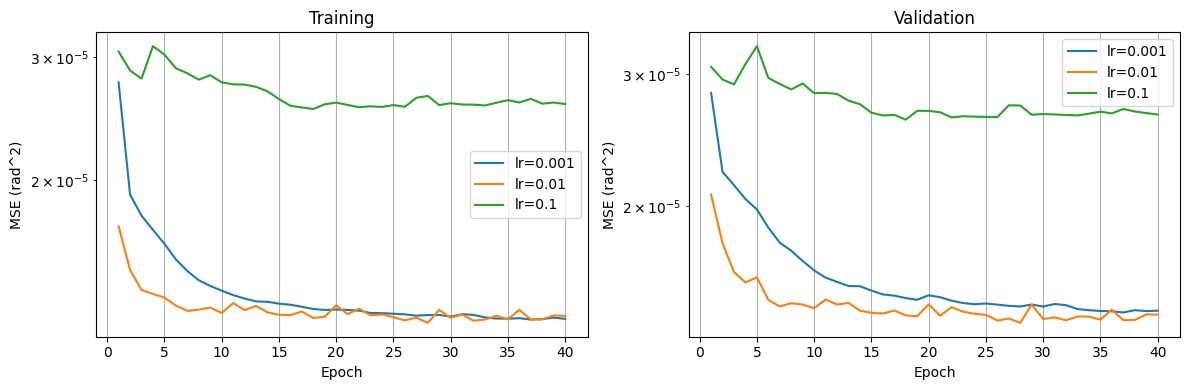

lr=0.001: best validation=1.443337e-05, epoch=37, reduction after epoch 1=48.98%.
lr=0.1: best validation=2.607923e-05, epoch=18, reduction after epoch 1=14.95%.
lr=0.01: best validation=1.397836e-05, epoch=28, reduction after epoch 1=32.54%.
Validation-selected learning rate: 0.01.
The following ablations hold this rate, widths and epoch budget fixed; they are not separately tuned optima for every configuration.
Compared with the smallest rate 0.001, rate 0.01 reduces best validation MSE by 3.15%.
Best epochs: selected rate=28, smallest rate=37.
lr=0.001: validation MSE at epoch 10=1.641996e-05; last-ten-epoch validation range=1.443337e-05 to 1.481080e-05.
lr=0.01: validation MSE at epoch 10=1.462035e-05; last-ten-epoch validation range=1.409024e-05 to 1.455606e-05.
lr=0.1: validation MSE at epoch 10=2.828057e-05; last-ten-epoch validation range=2.641756e-05 to 2.694107e-05.
The largest rate 0.1 settles in a narrow range of higher validation errors, consistent with an elevated error p

,n_episodes,seed,train_samples,best_epoch,train_MSE,val_MSE,training_seconds,optimizer_updates
0,9,42,8333,5,8.852112e-06,1.384983e-05,6.137118e+00,1320
1,18,42,16788,10,1.207098e-05,1.378581e-05,1.448546e+01,2640
2,27,42,22410,16,1.199826e-05,1.367976e-05,2.052351e+01,3520
3,36,42,27770,7,1.176922e-05,1.352443e-05,2.415291e+01,4360
4,9,52,6424,12,1.007395e-05,1.393681e-05,4.921970e+00,1040
5,18,52,12857,4,9.164835e-06,1.366907e-05,1.145059e+01,2040
6,27,52,19519,15,1.350081e-05,1.375228e-05,1.877238e+01,3080
7,36,52,27770,12,1.152223e-05,1.361997e-05,2.442151e+01,4360
8,9,62,6541,13,9.534529e-06,1.396689e-05,4.757158e+00,1040
9,18,62,14690,13,7.838082e-06,1.360235e-05,1.244266e+01,2320


,samples_mean,train_mean,train_std,val_mean,val_std,training_seconds_mean
n_episodes,,,,,,
9,7.099333e+03,9.486864e-06,6.123124e-07,1.391785e-05,6.079381e-08,5.272082e+00
18,1.477833e+04,9.691298e-06,2.165000e-06,1.368574e-05,9.286117e-08,1.279290e+01
27,2.130167e+04,1.144998e-05,2.372969e-06,1.363408e-05,1.464907e-07,1.984120e+01
36,2.777000e+04,1.165835e-05,1.254179e-07,1.359500e-05,6.198833e-08,2.488600e+01


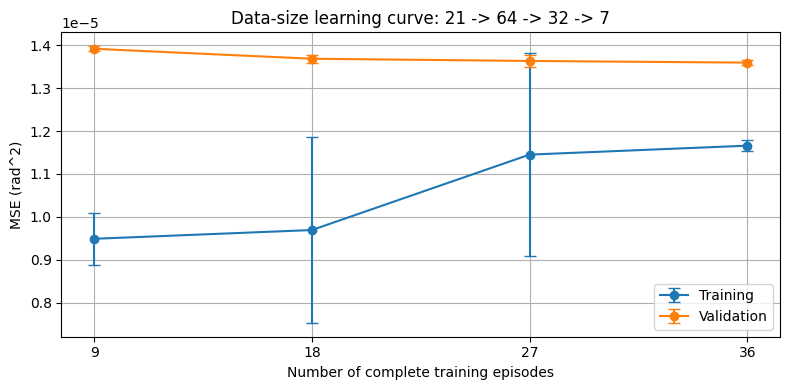

9 -> 18 training episodes: mean validation MSE reduction +1.67%.
18 -> 27 training episodes: mean validation MSE reduction +0.38%.
27 -> 36 training episodes: mean validation MSE reduction +0.29%.
The final increase still reduces mean validation MSE by 0.29%; this is evidence of a benefit within the tested range, not proof of sufficiency.
Only training and validation scores are used in this learning curve.
The 60 selected episodes contain 36 training episodes, not 60 training episodes.
The plot tests the value of 9-36 training trajectories against one fixed
validation partition; it cannot establish complete coverage of the robot domain.
Error bars are standard deviations over three repeats. At smaller sizes the
repeats change both the sampled trajectories and initialization, so this is
combined subset/optimization variability, not only initialization variability.
Subsets are nested within each repeat, and scalers are refitted on each subset.
The budget is 40 passes through each subset:

,architecture,hidden,n_layers,parameters,seed,best_epoch,train_MSE,val_MSE,training_seconds
0,1 hidden layer,"(128,)",1,3719,42,7,1.178193e-05,1.374918e-05,2.372482e+01
1,1 hidden layer,"(128,)",1,3719,52,6,1.182066e-05,1.375398e-05,2.160517e+01
2,1 hidden layer,"(128,)",1,3719,62,5,1.185618e-05,1.371833e-05,2.365176e+01
3,2 hidden layers,"(64, 32)",2,3719,42,7,1.176922e-05,1.352443e-05,2.415291e+01
4,2 hidden layers,"(64, 32)",2,3719,52,12,1.152223e-05,1.361997e-05,2.442151e+01
5,2 hidden layers,"(64, 32)",2,3719,62,5,1.168360e-05,1.364062e-05,2.608360e+01
6,3 hidden layers,"(56, 32, 16)",3,3703,42,12,1.153220e-05,1.364185e-05,2.556400e+01
7,3 hidden layers,"(56, 32, 16)",3,3703,52,33,1.123238e-05,1.373627e-05,2.536646e+01
8,3 hidden layers,"(56, 32, 16)",3,3703,62,13,1.151629e-05,1.366438e-05,2.449188e+01


,n_layers,parameters,train_mean,train_std,val_mean,val_std,training_seconds_mean,training_seconds_std
architecture,,,,,,,,
1 hidden layer,1,3719,1.181959e-05,3.713845e-08,1.374050e-05,1.934558e-08,2.299392e+01,1.203244e+00
2 hidden layers,2,3719,1.165835e-05,1.254179e-07,1.359500e-05,6.198833e-08,2.488600e+01,1.045804e+00
3 hidden layers,3,3703,1.142696e-05,1.686930e-07,1.368083e-05,4.931086e-08,2.514078e+01,5.705731e-01


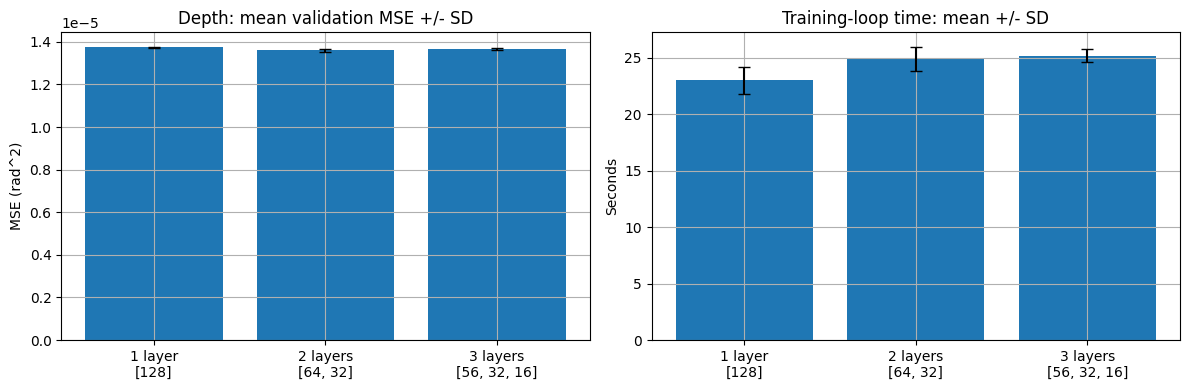

Lowest mean validation MSE in the depth comparison: 2 hidden layers
Two-layer mean validation MSE=1.359500e-05; best compared depth=1.359500e-05.
Two layers are supported within these architectures, seeds and shared budget; this is not proof that two layers are universally optimal.
The original two-layer network was a modest nonlinear starting point.
This comparison tests that choice rather than assuming that greater depth helps.
Parameter counts are nearly matched (3,719 / 3,719 / 3,703); input features,
data partitions, loss, optimizer, learning rate and epochs are held fixed.
Width changes with depth to keep capacity comparable, so this remains a
comparison of these architectures, not a proof about every network of each depth.
The same three seeds measure initialization/minibatch variability on one split.
Each architecture uses the learning rate chosen in the earlier baseline study,
not its separately optimized rate. Small differences need cautious interpretation.
Test values record

,val_mean,val_std
model,,
Original MLP,1.396133e-05,5.210405e-08
Aligned-loss MLP,1.394922e-05,1.432107e-07
Tracking-error MLP,1.394113e-05,2.947597e-08
History MLP,1.359500e-05,6.198833e-08
History MLP / 1 hidden layer,1.374050e-05,1.934558e-08
History MLP / 3 hidden layers,1.368083e-05,4.931086e-08


Final standalone MLP, chosen by mean validation MSE: History MLP
Hidden widths=(64, 32); fixed representative seed=42.
No small-subset result, random-seed winner or test result determines this choice.


,train_mean,val_mean,val_std,test_mean,test_std
model,,,,,
Original MLP,1.248738e-05,1.396133e-05,5.210405e-08,2.330698e-05,1.914466e-07
Aligned-loss MLP,1.247190e-05,1.394922e-05,1.432107e-07,2.325101e-05,2.144123e-07
Tracking-error MLP,1.238798e-05,1.394113e-05,2.947597e-08,2.339719e-05,4.496733e-07
History MLP,1.165835e-05,1.359500e-05,6.198833e-08,2.260875e-05,7.687284e-08


,model,seed,best_epoch,gamma,train_MSE,val_MSE,test_MSE
0,Hybrid history,42,17,1.000000e+00,1.162784e-05,1.309826e-05,2.310280e-05
1,Hybrid history,52,5,5.000000e-01,1.177651e-05,1.311288e-05,2.175488e-05
2,Hybrid history,62,34,1.000000e+00,1.186091e-05,1.315845e-05,2.179270e-05


,train_mean,val_mean,val_std,test_mean,test_std
model,,,,,
Hybrid history,1.175509e-05,1.312320e-05,3.139587e-08,2.221679e-05,7.675378e-07


Selected standalone configuration: scores across the three predeclared seeds.


,train_mean,val_mean,val_std,test_mean,test_std
model,,,,,
History MLP,1.165835e-05,1.359500e-05,6.198833e-08,2.260875e-05,7.687284e-08


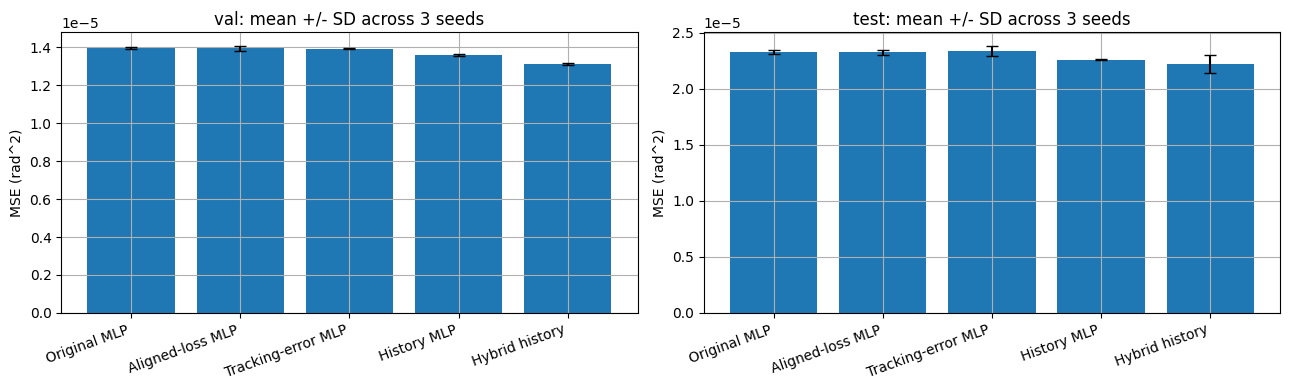

Original MLP -> Aligned-loss MLP: mean validation MSE change = +0.09% improvement.
Aligned-loss MLP -> Tracking-error MLP: mean validation MSE change = +0.06% improvement.
Tracking-error MLP -> History MLP: mean validation MSE change = +2.48% improvement.
Positive values mean improvement; negative values mean the added change did not help.
Three seeds measure optimization variability on ONE fixed split, not confidence across new datasets.


,Initial MLP,Final MLP,Persistence,Ridge raw,Ridge error,Ridge history,Hybrid history
train,1.259531e-05,1.176922e-05,3.132180e-05,1.232328e-05,1.232220e-05,1.185970e-05,1.162784e-05
val,1.443337e-05,1.352443e-05,3.116626e-05,1.348322e-05,1.348181e-05,1.315963e-05,1.309826e-05
test,2.468344e-05,2.252637e-05,5.148384e-05,2.219454e-05,2.219598e-05,2.178728e-05,2.310280e-05


,train,val,test
Joint 1,7.396769e-06,5.944832e-06,1.097160e-05
Joint 2,5.264209e-06,6.641247e-06,7.061552e-06
Joint 3,6.854181e-06,5.227098e-06,1.251853e-05
Joint 4,9.969969e-06,1.204577e-05,1.969483e-05
Joint 5,2.602912e-05,2.567709e-05,5.556495e-05
Joint 6,1.261165e-05,2.191003e-05,2.438051e-05
Joint 7,1.425867e-05,1.722491e-05,2.749261e-05


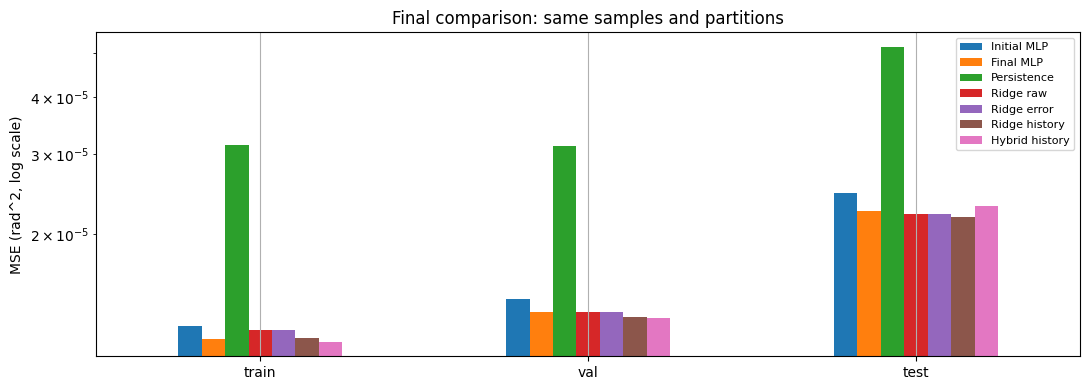

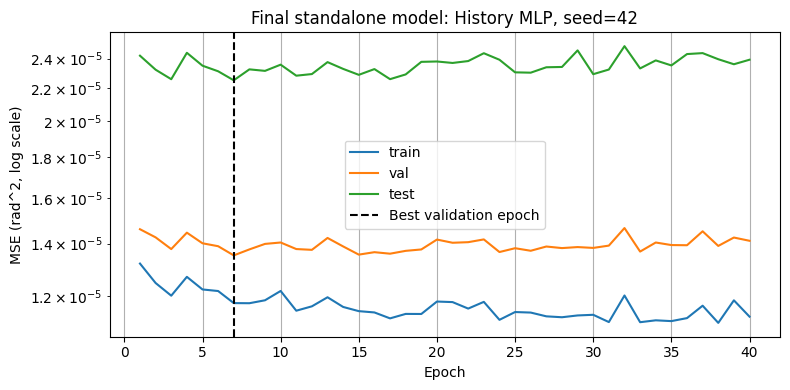

Final standalone MLP: best epoch=7, validation/train ratio=1.149
Training MSE, first -> last: 1.320609e-05 -> 1.131318e-05
Validation MSE, best -> last: 1.352443e-05 -> 1.411223e-05
Selected train/val/test MSE: 1.176922e-05 / 1.352443e-05 / 2.252637e-05
End-of-training validation rebound above the minimum: 4.35%.
There is a small late validation rebound while training improves overall. This gives limited evidence of late overfitting; the endpoints alone do not establish a persistent divergence of the curves.
MSE reduction versus persistence: train=62.42%, validation=56.61%.
The model learns useful signal on both training and validation data. The current evidence does not establish severe underfitting. Beating persistence alone cannot exclude remaining underfitting.
A split gap alone does not prove overfitting: episodes differ in task,
objects and motion. A lower Ridge error also cannot by itself identify underfitting.
Training-fit, optimization and controlled-capacity comparisons infor

In [ ]:
# Q7 - Learning rates, controlled ablations, repeated seeds and FINAL evaluation
# Part A: required learning-rate study, original features/loss and one fixed seed.
lr_runs = {0.001: baseline}
for lr in LEARNING_RATES:
    if lr not in lr_runs:
        lr_runs[lr] = train_regressor(base_lr=lr)
lr_rows = []
for lr in LEARNING_RATES:
    run = lr_runs[lr]
    selected = run['history'].loc[run['history'].epoch.eq(run['best_epoch'])].iloc[0]
    lr_rows.append({'learning_rate': lr, 'best_epoch': run['best_epoch'],
                    'train_MSE': selected['train'], 'val_MSE': selected['val']})
learning_rates = pd.DataFrame(lr_rows)
display(learning_rates)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for lr in sorted(lr_runs):
    for axis, split in zip(axes, ['train', 'val']):
        history = lr_runs[lr]['history']
        axis.plot(history.epoch, history[split], label=f'lr={lr:g}')
for axis, title in zip(axes, ['Training', 'Validation']):
    axis.set(title=title, xlabel='Epoch', ylabel='MSE (rad^2)', yscale='log')
    axis.legend()
plt.tight_layout(); plt.show()
selected_lr = float(learning_rates.loc[learning_rates.val_MSE.idxmin(), 'learning_rate'])
for lr, run in lr_runs.items():
    history = run['history']
    reduction = 100*(1-history.val.min()/history.val.iloc[0])
    print(f'lr={lr:g}: best validation={history.val.min():.6e}, '
          f'epoch={run["best_epoch"]}, reduction after epoch 1={reduction:.2f}%.')
    if reduction < 5:
        print('  Little validation improvement within this budget; a large step may impede learning.')
print(f'Validation-selected learning rate: {selected_lr:g}.')
print('The following ablations hold this rate, widths and epoch budget fixed; '
      'they are not separately tuned optima for every configuration.')

# Explain the observed learning-rate trade-off, using this run's actual results.
lr_table = learning_rates.set_index('learning_rate')
reference_lr = min(lr_runs)
chosen_mse = float(lr_table.loc[selected_lr, 'val_MSE'])
reference_mse = float(lr_table.loc[reference_lr, 'val_MSE'])
lr_gain = 100 * (1 - chosen_mse / max(reference_mse, 1e-15))
print(f'Compared with the smallest rate {reference_lr:g}, rate {selected_lr:g} '
      f'reduces best validation MSE by {lr_gain:.2f}%.')
print(f'Best epochs: selected rate={int(lr_table.loc[selected_lr, "best_epoch"])}, '
      f'smallest rate={int(lr_table.loc[reference_lr, "best_epoch"])}.')
for lr in sorted(lr_runs):
    history = lr_runs[lr]['history']
    early = history.iloc[min(9, len(history)-1)]
    late = history.val.tail(10)
    print(f'lr={lr:g}: validation MSE at epoch {int(early.epoch)}={early.val:.6e}; '
          f'last-ten-epoch validation range={late.min():.6e} to {late.max():.6e}.')
largest_lr = max(lr_runs)
largest_late = lr_runs[largest_lr]['history'].val.tail(10)
relative_range = (largest_late.max() - largest_late.min()) / max(largest_late.mean(), 1e-15)
if float(lr_table.loc[largest_lr, 'val_MSE']) > chosen_mse and relative_range < 0.1:
    print(f'The largest rate {largest_lr:g} settles in a narrow range of higher '
          'validation errors, consistent with an elevated error plateau. '
          'A large update step may impede further optimization.')
print('''The curves and epoch-specific errors describe convergence speed within
the same 40-epoch budget. The selected rate gives the lowest best validation MSE
in this sweep. Every completed run has finite recorded losses, so a higher
error plateau should not be described as numerical divergence.
The learning-rate sweep uses one seed; the later comparisons assess variability
across three seeds while sharing this validation-selected rate.
''')

# Part B: one change at a time; all models have the same sample rows and split.
CONFIGS = {
    'Original MLP': ('raw', 'standardized'),
    'Aligned-loss MLP': ('raw', 'aligned'),
    'Tracking-error MLP': ('error', 'aligned'),
    'History MLP': ('history', 'aligned'),
}
experiment_runs, seed_rows = {}, []
for label, (feature, loss_name) in CONFIGS.items():
    experiment_runs[label] = {}
    for seed in SEEDS:
        run = (lr_runs[selected_lr] if label == 'Original MLP' and seed == SEED
               else train_regressor(feature=feature, loss_name=loss_name,
                                    base_lr=selected_lr, seed=seed))
        experiment_runs[label][seed] = run
        seed_rows.append({'model': label, 'seed': seed, 'best_epoch': run['best_epoch'],
                          'train_MSE': mean_squared_error(data['train']['y_raw'], predict_run(run, 'train')),
                          'val_MSE': mean_squared_error(data['val']['y_raw'], predict_run(run, 'val'))})
seed_results = pd.DataFrame(seed_rows)
ablation_summary = seed_results.groupby('model', sort=False).agg(
    train_mean=('train_MSE', 'mean'), val_mean=('val_MSE', 'mean'), val_std=('val_MSE', 'std'))
# Select a configuration by MEAN validation error, never by the best random seed.
feature_choice = ablation_summary.val_mean.idxmin()
print('Best two-hidden-layer feature configuration by mean validation MSE:', feature_choice)
print('Q7 also evaluates depth before the final standalone model is selected.')

# Part C: optional Ridge + residual MLP, using the SAME history features as Ridge.
hybrid_runs, hybrid_rows, gamma_rows = {}, [], []
for seed in SEEDS:
    run = train_regressor(feature='history', loss_name='aligned', base_lr=selected_lr,
                          seed=seed, ridge=ridge_models['history'])
    # Select gamma on validation at the gamma=1 validation-selected checkpoint.
    candidates = {gamma: mean_squared_error(data['val']['y_raw'],
                                            predict_run(run, 'val', gamma=gamma))
                  for gamma in GAMMAS}
    run['gamma'] = min(candidates, key=candidates.get)
    np.testing.assert_allclose(predict_run(run, 'val', gamma=0.0),
                               ridge_predictions['history']['val'], rtol=1e-6, atol=1e-8)
    hybrid_runs[seed] = run
    gamma_rows.extend({'seed': seed, 'gamma': gamma, 'val_MSE': value}
                      for gamma, value in candidates.items())
    hybrid_rows.append({'model': 'Hybrid history', 'seed': seed,
                        'best_epoch': run['best_epoch'], 'gamma': run['gamma'],
                        'train_MSE': mean_squared_error(data['train']['y_raw'], predict_run(run, 'train')),
                        'val_MSE': candidates[run['gamma']]})
    print(f'Hybrid seed={seed}: selected gamma={run["gamma"]:g}' +
          (' (no learned correction; same predictor as Ridge).' if run['gamma'] == 0 else '.'))

# Part D: how much do additional independent training trajectories help?
# Validation/test episodes stay fixed. This study does not select a new split.
TRAIN_SIZES = [9, 18, 27, 36]
assert len(split_ids['train']) == TRAIN_SIZES[-1]
heldout_ids = set(split_ids['val']) | set(split_ids['test'])
size_rows, size_manifest = [], []
size_runs = {}
for seed in SEEDS:
    # Within each repeat, every larger subset contains the preceding subset.
    ordered_ids = np.random.default_rng(seed).permutation(sorted(split_ids['train']))
    previous_ids = set()
    for n_episodes in TRAIN_SIZES:
        chosen_ids = ordered_ids[:n_episodes]
        assert previous_ids.issubset(set(chosen_ids))
        assert set(chosen_ids).isdisjoint(heldout_ids)
        previous_ids = set(chosen_ids)
        mask = data['train']['info'].episode_index.isin(chosen_ids).to_numpy()
        assert data['train']['info'].loc[mask, 'episode_index'].nunique() == n_episodes
        if n_episodes == TRAIN_SIZES[-1]:
            # Identical rows, preprocessing, model, learning rate and seed: reuse.
            run = experiment_runs['History MLP'][seed]
        else:
            subset_x_scaler = StandardScaler().fit(data['train']['X_raw']['history'][mask])
            subset_y_scaler = StandardScaler().fit(data['train']['y_raw'][mask])
            assert int(subset_x_scaler.n_samples_seen_) == int(mask.sum())
            assert int(subset_y_scaler.n_samples_seen_) == int(mask.sum())
            subset_data = {}
            for split in ['train', 'val']:
                rows = mask if split == 'train' else np.ones(len(data['val']['y_raw']), dtype=bool)
                raw_x = data[split]['X_raw']['history'][rows]
                raw_y = data[split]['y_raw'][rows]
                subset_data[split] = {
                    'X_raw': {'history': raw_x},
                    'X': {'history': torch.from_numpy(subset_x_scaler.transform(raw_x).astype('float32'))},
                    'y_raw': raw_y,
                    'y': torch.from_numpy(subset_y_scaler.transform(raw_y).astype('float32')),
                    'info': data[split]['info'].loc[rows].reset_index(drop=True),
                }
            assert 'test' not in subset_data
            np.testing.assert_array_equal(subset_data['val']['y_raw'], data['val']['y_raw'])
            run = train_regressor(feature='history', loss_name='aligned',
                                  base_lr=selected_lr, seed=seed, hidden=(64, 32),
                                  dataset=subset_data, target_scaler=subset_y_scaler,
                                  eval_splits=('train', 'val'))
        size_runs[(n_episodes, seed)] = run
        row = {
            'n_episodes': n_episodes, 'seed': seed, 'train_samples': int(mask.sum()),
            'best_epoch': run['best_epoch'],
            'train_MSE': mean_squared_error(run['data']['train']['y_raw'], predict_run(run, 'train')),
            'val_MSE': mean_squared_error(data['val']['y_raw'], predict_run(run, 'val')),
            'training_seconds': run['training_seconds'],
            'optimizer_updates': EPOCHS * int(np.ceil(mask.sum()/BATCH_SIZE)),
            'episode_ids': json.dumps([int(ep) for ep in chosen_ids]),
        }
        size_rows.append(row)
        size_manifest.append({'n_episodes': n_episodes, 'seed': seed,
                              'train_samples': int(mask.sum()),
                              'episode_ids': [int(ep) for ep in chosen_ids]})
        print(f'Data-size study: {n_episodes} episodes, seed={seed}, '
              f'{int(mask.sum())} samples, validation MSE={row["val_MSE"]:.6e}')

size_results = pd.DataFrame(size_rows)
size_summary = size_results.groupby('n_episodes').agg(
    samples_mean=('train_samples', 'mean'),
    train_mean=('train_MSE', 'mean'), train_std=('train_MSE', 'std'),
    val_mean=('val_MSE', 'mean'), val_std=('val_MSE', 'std'),
    training_seconds_mean=('training_seconds', 'mean'))
display(size_results.drop(columns='episode_ids'))
display(size_summary)
fig, axis = plt.subplots(figsize=(8, 4))
for split, label in [('train', 'Training'), ('val', 'Validation')]:
    axis.errorbar(size_summary.index, size_summary[f'{split}_mean'],
                   yerr=size_summary[f'{split}_std'], marker='o', capsize=4, label=label)
axis.set(title='Data-size learning curve: 21 -> 64 -> 32 -> 7',
         xlabel='Number of complete training episodes', ylabel='MSE (rad^2)')
axis.set_xticks(TRAIN_SIZES)
axis.legend(); plt.tight_layout(); plt.show()
for smaller, larger in zip(TRAIN_SIZES[:-1], TRAIN_SIZES[1:]):
    gain = 100*(1-size_summary.loc[larger, 'val_mean']/size_summary.loc[smaller, 'val_mean'])
    print(f'{smaller} -> {larger} training episodes: mean validation MSE reduction {gain:+.2f}%.')
size_last_gain = 100*(1-size_summary.loc[36, 'val_mean']/size_summary.loc[27, 'val_mean'])
if size_last_gain > 0:
    print(f'The final increase still reduces mean validation MSE by {size_last_gain:.2f}%; '
          'this is evidence of a benefit within the tested range, not proof of sufficiency.')
else:
    print('The final increase does not reduce mean validation MSE in these repeats; '
          'this alone does not establish a true plateau or prove that more data cannot help.')
print('''Only training and validation scores are used in this learning curve.
The 60 selected episodes contain 36 training episodes, not 60 training episodes.
The plot tests the value of 9-36 training trajectories against one fixed
validation partition; it cannot establish complete coverage of the robot domain.
Error bars are standard deviations over three repeats. At smaller sizes the
repeats change both the sampled trajectories and initialization, so this is
combined subset/optimization variability, not only initialization variability.
Subsets are nested within each repeat, and scalers are refitted on each subset.
The budget is 40 passes through each subset: more samples also mean more
optimizer updates. This is a fixed-epoch learning curve, not an equal-update
test that isolates data volume from optimization effort. Training times exclude
evaluation and checkpoint copying and remain specific to the current hardware.
The complete 36-episode runs are reused because their settings are identical.
''')
size_results.to_csv(OUTPUT_DIR / 'q7_data_size_results.csv', index=False)
size_summary.to_csv(OUTPUT_DIR / 'q7_data_size_summary.csv')
(OUTPUT_DIR / 'q7_data_size_manifest.json').write_text(
    json.dumps({'fixed_validation_ids': [int(ep) for ep in split_ids['val']],
                'fixed_test_ids': [int(ep) for ep in split_ids['test']],
                'subsets': size_manifest}, indent=2), encoding='utf-8')

# Part E: why two hidden layers? Compare depth at nearly equal parameter counts.
DEPTH_CONFIGS = {
    '1 hidden layer': (128,),
    '2 hidden layers': (64, 32),
    '3 hidden layers': (56, 32, 16),
}
depth_runs, depth_rows = {}, []
for label, hidden in DEPTH_CONFIGS.items():
    depth_runs[label] = {}
    for seed in SEEDS:
        if hidden == (64, 32):
            run = experiment_runs['History MLP'][seed]
        else:
            # No test scores are computed during these new depth experiments.
            # Snapshots permit a final test curve after all choices are frozen.
            run = train_regressor(feature='history', loss_name='aligned',
                                  base_lr=selected_lr, seed=seed, hidden=hidden,
                                  eval_splits=('train', 'val'), store_checkpoints=True)
        depth_runs[label][seed] = run
        parameters = sum(parameter.numel() for parameter in run['model'].parameters())
        depth_rows.append({
            'architecture': label, 'hidden': str(hidden), 'n_layers': len(hidden),
            'parameters': parameters, 'seed': seed, 'best_epoch': run['best_epoch'],
            'train_MSE': mean_squared_error(data['train']['y_raw'], predict_run(run, 'train')),
            'val_MSE': mean_squared_error(data['val']['y_raw'], predict_run(run, 'val')),
            'training_seconds': run['training_seconds'],
        })

depth_results = pd.DataFrame(depth_rows)
depth_summary = depth_results.groupby('architecture', sort=False).agg(
    n_layers=('n_layers', 'first'), parameters=('parameters', 'first'),
    train_mean=('train_MSE', 'mean'), train_std=('train_MSE', 'std'),
    val_mean=('val_MSE', 'mean'), val_std=('val_MSE', 'std'),
    training_seconds_mean=('training_seconds', 'mean'),
    training_seconds_std=('training_seconds', 'std'))
np.testing.assert_array_equal(depth_summary['parameters'].to_numpy(), [3719, 3719, 3703])
display(depth_results)
display(depth_summary)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(len(DEPTH_CONFIGS))
labels = ['1 layer\n[128]', '2 layers\n[64, 32]', '3 layers\n[56, 32, 16]']
axes[0].bar(x, depth_summary.val_mean, yerr=depth_summary.val_std, capsize=4)
axes[0].set(title='Depth: mean validation MSE +/- SD', ylabel='MSE (rad^2)')
axes[1].bar(x, depth_summary.training_seconds_mean,
             yerr=depth_summary.training_seconds_std, capsize=4)
axes[1].set(title='Training-loop time: mean +/- SD', ylabel='Seconds')
for axis in axes:
    axis.set_xticks(x, labels)
plt.tight_layout(); plt.show()
best_depth = depth_summary.val_mean.idxmin()
two_layer_val = float(depth_summary.loc['2 hidden layers', 'val_mean'])
best_depth_val = float(depth_summary.loc[best_depth, 'val_mean'])
print('Lowest mean validation MSE in the depth comparison:', best_depth)
print(f'Two-layer mean validation MSE={two_layer_val:.6e}; '
      f'best compared depth={best_depth_val:.6e}.')
if best_depth == '2 hidden layers':
    print('Two layers are supported within these architectures, seeds and shared budget; '
          'this is not proof that two layers are universally optimal.')
else:
    print(f'{best_depth} has the lower validation mean. The results do not justify '
          'claiming that the original two-layer choice is optimal.')
print('''The original two-layer network was a modest nonlinear starting point.
This comparison tests that choice rather than assuming that greater depth helps.
Parameter counts are nearly matched (3,719 / 3,719 / 3,703); input features,
data partitions, loss, optimizer, learning rate and epochs are held fixed.
Width changes with depth to keep capacity comparable, so this remains a
comparison of these architectures, not a proof about every network of each depth.
The same three seeds measure initialization/minibatch variability on one split.
Each architecture uses the learning rate chosen in the earlier baseline study,
not its separately optimized rate. Small differences need cautious interpretation.
Test values recorded earlier for the reused two-layer model are not consulted
by either study. Final selection and test reporting follow these comparisons.
''')
depth_results.to_csv(OUTPUT_DIR / 'q7_depth_results.csv', index=False)
depth_summary.to_csv(OUTPUT_DIR / 'q7_depth_summary.csv')

# Part F: choose among full-training-set standalone MLPs using validation only.
# Reduced-data runs diagnose data sufficiency; they are not final candidates.
candidate_runs = dict(experiment_runs)
for label in ['1 hidden layer', '3 hidden layers']:
    candidate_runs[f'History MLP / {label}'] = depth_runs[label]
selection_rows = []
for label, runs in candidate_runs.items():
    values = [run['history'].val.min() for run in runs.values()]
    selection_rows.append({'model': label, 'val_mean': np.mean(values),
                           'val_std': np.std(values, ddof=1)})
selection_summary = pd.DataFrame(selection_rows).set_index('model')
final_config = selection_summary.val_mean.idxmin()
final_run = candidate_runs[final_config][SEED]
display(selection_summary)
print('Final standalone MLP, chosen by mean validation MSE:', final_config)
print(f'Hidden widths={final_run["hidden"]}; fixed representative seed={SEED}.')
print('No small-subset result, random-seed winner or test result determines this choice.')

# All model choices are now frozen. Reconstruct a new-depth model's required
# test curve from saved epoch weights only if that model was selected.
if 'test' not in final_run['history']:
    assert len(final_run['checkpoints']) == EPOCHS
    selected_state = copy.deepcopy(final_run['model'].state_dict())
    test_curve = []
    for state in final_run['checkpoints']:
        final_run['model'].load_state_dict(state)
        test_curve.append(mean_squared_error(data['test']['y_raw'], predict_run(final_run, 'test')))
    final_run['model'].load_state_dict(selected_state)
    final_run['history']['test'] = test_curve
    print('Final test loss curve calculated after model selection; checkpoint selection is unchanged.')

# Test summaries below are descriptive, not selection.
seed_results['test_MSE'] = [
    mean_squared_error(data['test']['y_raw'], predict_run(experiment_runs[row.model][row.seed], 'test'))
    for row in seed_results.itertuples()
]
test_summary = seed_results.groupby('model', sort=False).test_MSE.agg(['mean', 'std'])
ablation_summary['test_mean'] = test_summary['mean']
ablation_summary['test_std'] = test_summary['std']
hybrid_seed_results = pd.DataFrame(hybrid_rows)
hybrid_seed_results['test_MSE'] = [
    mean_squared_error(data['test']['y_raw'], predict_run(hybrid_runs[seed], 'test')) for seed in SEEDS
]
hybrid_summary = hybrid_seed_results.groupby('model').agg(
    train_mean=('train_MSE', 'mean'), val_mean=('val_MSE', 'mean'), val_std=('val_MSE', 'std'),
    test_mean=('test_MSE', 'mean'), test_std=('test_MSE', 'std'))
final_seed_rows = []
for seed, run in candidate_runs[final_config].items():
    final_seed_rows.append({'model': final_config, 'seed': seed,
                            'best_epoch': run['best_epoch'],
                            **{f'{s}_MSE': mean_squared_error(data[s]['y_raw'], predict_run(run, s))
                               for s in data}})
final_seed_results = pd.DataFrame(final_seed_rows)
final_seed_summary = final_seed_results.groupby('model').agg(
    train_mean=('train_MSE', 'mean'), val_mean=('val_MSE', 'mean'), val_std=('val_MSE', 'std'),
    test_mean=('test_MSE', 'mean'), test_std=('test_MSE', 'std'))
display(ablation_summary)
display(hybrid_seed_results)
display(hybrid_summary)
print('Selected standalone configuration: scores across the three predeclared seeds.')
display(final_seed_summary)
comparison_summary = pd.concat([ablation_summary, hybrid_summary])
if final_config not in comparison_summary.index:
    comparison_summary = pd.concat([comparison_summary, final_seed_summary])
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
x = np.arange(len(comparison_summary))
for axis, split in zip(axes, ['val', 'test']):
    axis.bar(x, comparison_summary[f'{split}_mean'],
             yerr=comparison_summary[f'{split}_std'], capsize=4)
    axis.set_xticks(x, comparison_summary.index, rotation=20, ha='right')
    axis.set(title=f'{split}: mean +/- SD across 3 seeds', ylabel='MSE (rad^2)')
plt.tight_layout(); plt.show()
labels = list(CONFIGS)
for before, after in zip(labels[:-1], labels[1:]):
    gain = 100*(1-ablation_summary.loc[after, 'val_mean']/ablation_summary.loc[before, 'val_mean'])
    print(f'{before} -> {after}: mean validation MSE change = {gain:+.2f}% improvement.')
print('Positive values mean improvement; negative values mean the added change did not help.')
print('Three seeds measure optimization variability on ONE fixed split, not confidence across new datasets.')

# Part G: one consistent final model for metrics, curves, cases and saved weights.
final_predictions = {s: predict_run(final_run, s) for s in data}
final_predictors = {
    'Initial MLP': baseline_predictions, 'Final MLP': final_predictions,
    'Persistence': persistence_predictions,
    **{f'Ridge {feature}': ridge_predictions[feature] for feature in RAW_NAMES},
    'Hybrid history': {s: predict_run(hybrid_runs[SEED], s) for s in data},
}
final_metrics = evaluate_predictions(final_predictors)
final_joint_mse = pd.DataFrame({s: np.mean((final_predictions[s]-data[s]['y_raw'])**2, axis=0)
                                for s in data}, index=[f'Joint {j}' for j in range(1, 8)])
display(final_metrics)
display(final_joint_mse)
final_metrics.plot.bar(rot=0, logy=True, figsize=(11, 4))
plt.ylabel('MSE (rad^2, log scale)'); plt.title('Final comparison: same samples and partitions')
plt.legend(fontsize=8); plt.tight_layout(); plt.show()
plot_learning_curves(final_run, f'Final standalone model: {final_config}, seed={SEED}')
discuss_generalization(final_run, final_predictions, 'Final standalone MLP')
matched_ridge = f'Ridge {final_run["feature"]}'
ridge_gain = 100*(1-final_metrics.loc['test', 'Final MLP']/final_metrics.loc['test', matched_ridge])
print(f'Final MLP vs matching {matched_ridge}: test improvement={ridge_gain:+.2f}%.')
print('The hybrid remains an explicitly labelled extension, not a replacement for the main MLP.')

learning_rates.to_csv(OUTPUT_DIR / 'q7_learning_rates.csv', index=False)
seed_results.to_csv(OUTPUT_DIR / 'q7_seed_results.csv', index=False)
ablation_summary.to_csv(OUTPUT_DIR / 'q7_ablation_summary.csv')
hybrid_seed_results.to_csv(OUTPUT_DIR / 'q7_hybrid_seed_results.csv', index=False)
pd.DataFrame(gamma_rows).to_csv(OUTPUT_DIR / 'q7_gamma_validation.csv', index=False)
final_metrics.to_csv(OUTPUT_DIR / 'q7_final_metrics.csv')
final_joint_mse.to_csv(OUTPUT_DIR / 'q7_final_joint_mse.csv')
final_run['history'].to_csv(OUTPUT_DIR / 'q7_final_loss_history.csv', index=False)
selection_summary.to_csv(OUTPUT_DIR / 'q7_final_selection_validation.csv')
final_seed_results.to_csv(OUTPUT_DIR / 'q7_final_seed_results.csv', index=False)
final_seed_summary.to_csv(OUTPUT_DIR / 'q7_final_seed_summary.csv')
torch.save({
    'model_state_dict': {k: v.detach().cpu() for k, v in final_run['model'].state_dict().items()},
    'architecture': {'input_dim': len(RAW_NAMES[final_run['feature']]), 'hidden': list(final_run['hidden']),
                     'output_dim': 7, 'activation': 'relu'},
    'configuration': final_config, 'feature': final_run['feature'],
    'learning_rate': selected_lr, 'seed': SEED, 'best_epoch': int(final_run['best_epoch']),
    'loss': final_run['loss_name'], 'x_mean': x_scalers[final_run['feature']].mean_.tolist(),
    'x_scale': x_scalers[final_run['feature']].scale_.tolist(),
    'y_mean': y_scaler.mean_.tolist(), 'y_scale': y_scaler.scale_.tolist(), 'manifest': manifest,
}, OUTPUT_DIR / 'final_mlp.pt')
print('Final model and numerical results saved in:', OUTPUT_DIR.resolve())


# Question 8

,episode_index,frame_index,timestamp,MLP_MSE,Persistence_MSE,Matched_Ridge_MSE,motion_norm,input_z_norm,task,case
263,26,106,3.533333e+00,1.325356e-07,1.846574e-05,8.245849e-07,1.136926e-02,3.307289e+00,reach,"Low error, moving"
6389,133,543,1.810000e+01,1.530495e-07,2.030382e-05,4.297289e-07,1.192169e-02,5.859442e+00,wrap,"Low error, moving"
574,40,101,3.366667e+00,1.954804e-07,1.350559e-05,5.604210e-08,9.723124e-03,2.489354e+00,reach,"Low error, moving"
4237,107,178,5.933333e+00,1.496093e-02,2.126304e-02,1.493767e-02,3.857996e-01,1.053768e+01,press,High error
36,0,37,1.233333e+00,8.492197e-03,1.302258e-02,8.932712e-03,3.019239e-01,1.049818e+01,reach,High error
3796,104,407,1.356667e+01,5.063317e-03,7.099333e-03,5.003807e-03,2.229245e-01,8.729698e+00,wipe,High error


Final independent MLP: History MLP | matched Ridge input: history
Compare both baselines: low absolute error alone does not prove an advantage.
Low error | Past the mug and sponge use your left hand to approach the cubes.
High error | Press the gel pad with your left hand, leaving the bowl and TV remote in place.


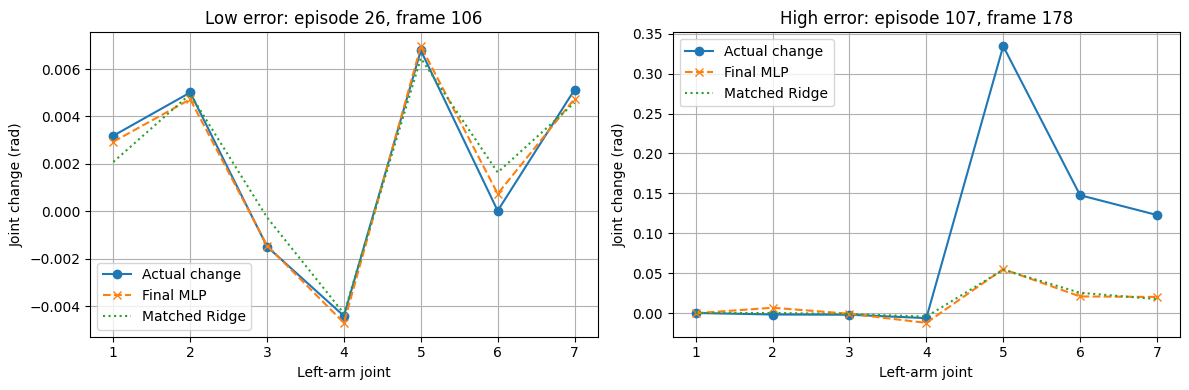

Test median motion norm: 8.080062e-03 rad
High-error examples mean motion norm: 3.035493e-01 rad (37.57 x the test median)
Test median standardized-input norm: 4.907
High-error examples mean standardized-input norm: 9.922
These high-error inputs have a larger average norm; that alone does not establish OOD.
A norm is not a density estimate: unusual feature combinations may have
ordinary norms. Large target changes, missing context, noise and control delay
are hypotheses to investigate, not verified causes of these errors.
These cases describe prediction accuracy, not physical task execution success.

Test groups use the training 90th-percentile threshold: 2.133515e-02 rad


,samples,sample_%,Final_MLP_MSE,Matched_Ridge_MSE,Persistence_MSE
group,,,,,
Ordinary motion,6574,8.536554e+01,8.952969e-06,8.578776e-06,1.261175e-05
Large motion,1127,1.463446e+01,1.017026e-04,9.883503e-05,2.782327e-04


All test samples remain in the overall MSE; test-group sizes need not be 90/10.


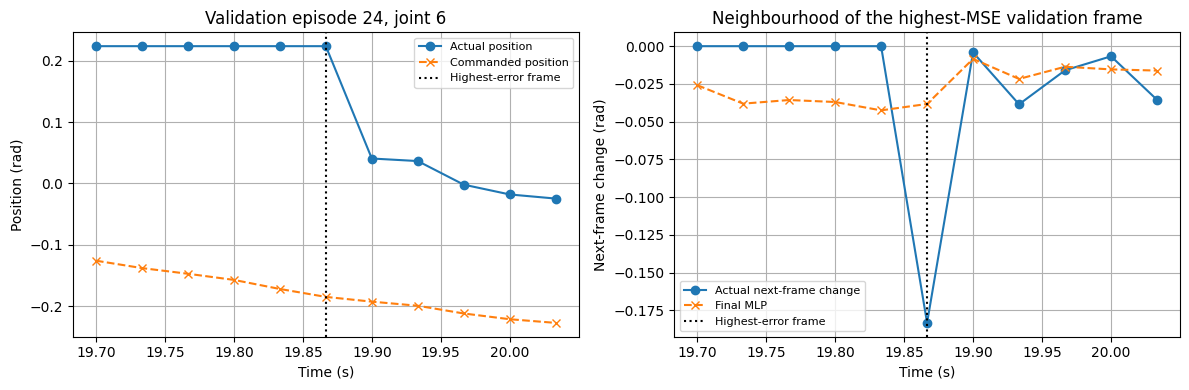

Diagnostic questions: is the change supported by nearby positions and
commands, or does it resemble an isolated jump or lag? This window can expose
patterns but cannot by itself distinguish sensor error from genuine fast motion.
No sample is deleted and no parameter is changed as a result of this plot.

Observed validation failure: episode 24, joint 6, frame 596 -> 597.
Actual next-frame change=-0.183214 rad; predicted change=-0.038264 rad.
5 of the 5 preceding local next-frame changes for this joint are approximately zero.
The predicted displacement magnitude is 79.12% too small.
The predicted direction agrees with the observed direction.
This window shows a local mismatch in the timing or size of joint motion.
Longer temporal history or contact information could help the model predict
this type of change.
These are hypotheses for further experiments. The trace alone cannot establish
whether the observed change reflects physical motion, recording effects or delay.



In [ ]:
# Q8 - Specific successes, failures and motion diagnostics of the final MLP
# All examples use the same validation-selected independent MLP as the final evaluation in Q7.
feature = final_run['feature']
truth = data['test']['y_raw']
test_prediction = final_predictions['test']
matched_ridge = ridge_predictions[feature]['test']
case_mse = np.mean((test_prediction - truth)**2, axis=1)
motion_size = np.linalg.norm(truth, axis=1)
cases = data['test']['info'].copy()
cases['MLP_MSE'] = case_mse
cases['Persistence_MSE'] = np.mean(truth**2, axis=1)
cases['Matched_Ridge_MSE'] = np.mean((matched_ridge - truth)**2, axis=1)
cases['motion_norm'] = motion_size
cases['input_z_norm'] = np.linalg.norm(data['test']['X'][feature].numpy(), axis=1)
cases['task'] = cases.episode_index.map(metadata.motor_primitive)

# Pick the worst distinct episodes first, then low-error moving cases from others.
# This keeps six different episodes and does not present stationary frames as success.
bad = cases.sort_values('MLP_MSE', ascending=False).drop_duplicates('episode_index').head(3)
moving = cases[cases.motion_norm > max(float(np.median(motion_size)), 1e-8)]
good = (moving[~moving.episode_index.isin(bad.episode_index)]
        .sort_values('MLP_MSE').drop_duplicates('episode_index').head(3))
if good.empty:
    raise RuntimeError('No moving examples outside the high-error episodes.')
selected_cases = pd.concat([good.assign(case='Low error, moving'),
                            bad.assign(case='High error')])
display(selected_cases)
print('Final independent MLP:', final_config, '| matched Ridge input:', feature)
print('Compare both baselines: low absolute error alone does not prove an advantage.')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, index, label in [(axes[0], good.index[0], 'Low error'),
                           (axes[1], bad.index[0], 'High error')]:
    row = cases.loc[index]
    axis.plot(range(1, 8), truth[index], 'o-', label='Actual change')
    axis.plot(range(1, 8), test_prediction[index], 'x--', label='Final MLP')
    axis.plot(range(1, 8), matched_ridge[index], ':', label='Matched Ridge')
    axis.set(title=f'{label}: episode {int(row.episode_index)}, frame {int(row.frame_index)}',
             xlabel='Left-arm joint', ylabel='Joint change (rad)')
    axis.legend()
    print(label, '|', metadata.loc[int(row.episode_index), 'caption'])
plt.tight_layout(); plt.show()

median_motion = float(np.median(motion_size))
high_motion = float(bad.motion_norm.mean())
median_input_norm = float(cases.input_z_norm.median())
high_input_norm = float(bad.input_z_norm.mean())
print(f'Test median motion norm: {median_motion:.6e} rad')
print(f'High-error examples mean motion norm: {high_motion:.6e} rad '
      f'({high_motion/max(median_motion, 1e-12):.2f} x the test median)')
print(f'Test median standardized-input norm: {median_input_norm:.3f}')
print(f'High-error examples mean standardized-input norm: {high_input_norm:.3f}')
if high_input_norm > median_input_norm:
    print('These high-error inputs have a larger average norm; that alone does not establish OOD.')
else:
    print('These high-error inputs do not have a larger average norm; this is not evidence of OOD.')
print('''A norm is not a density estimate: unusual feature combinations may have
ordinary norms. Large target changes, missing context, noise and control delay
are hypotheses to investigate, not verified causes of these errors.
These cases describe prediction accuracy, not physical task execution success.
''')

# The threshold is fixed from training targets; never remove hard test samples.
group_rows = []
for label, mask in [('Ordinary motion', motion_size <= motion_threshold),
                    ('Large motion', motion_size > motion_threshold)]:
    group_rows.append({
        'group': label, 'samples': int(mask.sum()), 'sample_%': 100*mask.mean(),
        'Final_MLP_MSE': float(case_mse[mask].mean()) if mask.any() else np.nan,
        'Matched_Ridge_MSE': float(cases.loc[mask, 'Matched_Ridge_MSE'].mean()) if mask.any() else np.nan,
        'Persistence_MSE': float(cases.loc[mask, 'Persistence_MSE'].mean()) if mask.any() else np.nan,
    })
motion_groups = pd.DataFrame(group_rows).set_index('group')
print(f'Test groups use the training 90th-percentile threshold: {motion_threshold:.6e} rad')
display(motion_groups)
print('All test samples remain in the overall MSE; test-group sizes need not be 90/10.')

# Inspect a VALIDATION failure over time without using test cases to change the model.
val_truth = data['val']['y_raw']
val_prediction = final_predictions['val']
val_errors = (val_prediction - val_truth)**2
worst_index = int(val_errors.mean(axis=1).argmax())
worst_joint = int(val_errors[worst_index].argmax())
val_info = data['val']['info']
val_episode = int(val_info.loc[worst_index, 'episode_index'])
ordered = val_info[val_info.episode_index.eq(val_episode)].sort_values('frame_index').index.to_numpy()
position = int(np.flatnonzero(ordered == worst_index)[0])
window = ordered[max(0, position-5):min(len(ordered), position+6)]
times = val_info.loc[window, 'timestamp'].to_numpy()
raw_val = data['val']['X_raw']['raw']
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(times, raw_val[window, worst_joint], 'o-', label='Actual position')
axes[0].plot(times, raw_val[window, 7+worst_joint], 'x--', label='Commanded position')
axes[0].set(title=f'Validation episode {val_episode}, joint {worst_joint+1}',
            xlabel='Time (s)', ylabel='Position (rad)')
axes[1].plot(times, val_truth[window, worst_joint], 'o-', label='Actual next-frame change')
axes[1].plot(times, val_prediction[window, worst_joint], 'x--', label='Final MLP')
axes[1].set(title='Neighbourhood of the highest-MSE validation frame',
            xlabel='Time (s)', ylabel='Next-frame change (rad)')
for axis in axes:
    axis.axvline(val_info.loc[worst_index, 'timestamp'], color='black', linestyle=':',
                 label='Highest-error frame')
    axis.legend(fontsize=8)
plt.tight_layout(); plt.show()
print('''Diagnostic questions: is the change supported by nearby positions and
commands, or does it resemble an isolated jump or lag? This window can expose
patterns but cannot by itself distinguish sensor error from genuine fast motion.
No sample is deleted and no parameter is changed as a result of this plot.
''')
# Describe the observed failure, including the transition represented by its target.
case_frame = int(val_info.loc[worst_index, 'frame_index'])
actual_change = float(val_truth[worst_index, worst_joint])
predicted_change = float(val_prediction[worst_index, worst_joint])
preceding = ordered[max(0, position-5):position]
preceding_zeros = int(np.isclose(val_truth[preceding, worst_joint], 0, atol=1e-8).sum())
print(f'Observed validation failure: episode {val_episode}, joint {worst_joint+1}, '
      f'frame {case_frame} -> {case_frame+1}.')
print(f'Actual next-frame change={actual_change:+.6f} rad; '
      f'predicted change={predicted_change:+.6f} rad.')
print(f'{preceding_zeros} of the {len(preceding)} preceding local next-frame '
      'changes for this joint are approximately zero.')
if abs(actual_change) > 1e-12:
    magnitude_gap = 100 * (1 - abs(predicted_change) / abs(actual_change))
    if magnitude_gap >= 0:
        print(f'The predicted displacement magnitude is {magnitude_gap:.2f}% too small.')
    else:
        print(f'The predicted displacement magnitude is {-magnitude_gap:.2f}% too large.')
    if actual_change * predicted_change < 0:
        print('The prediction also has the opposite direction to the observed change.')
    elif actual_change * predicted_change > 0:
        print('The predicted direction agrees with the observed direction.')
else:
    print('The observed change is approximately zero; a relative magnitude error is undefined.')
print('''This window shows a local mismatch in the timing or size of joint motion.
Longer temporal history or contact information could help the model predict
this type of change.
These are hypotheses for further experiments. The trace alone cannot establish
whether the observed change reflects physical motion, recording effects or delay.
''')

validation_window = val_info.loc[window].copy()
validation_window['joint'] = worst_joint + 1
validation_window['position'] = raw_val[window, worst_joint]
validation_window['command'] = raw_val[window, 7+worst_joint]
validation_window['actual_change'] = val_truth[window, worst_joint]
validation_window['predicted_change'] = val_prediction[window, worst_joint]
selected_cases.to_csv(OUTPUT_DIR / 'q8_cases.csv', index_label='test_sample_index')
motion_groups.to_csv(OUTPUT_DIR / 'q8_motion_groups.csv')
validation_window.to_csv(OUTPUT_DIR / 'q8_validation_window.csv', index_label='validation_sample_index')


# Question 9

In [ ]:
# Q9 - Discussion, limitations and future work based on the actual results
initial_test = float(final_metrics.loc['test', 'Initial MLP'])
final_test = float(final_metrics.loc['test', 'Final MLP'])
matched_name = f"Ridge {final_run['feature']}"
matched_test = float(final_metrics.loc['test', matched_name])
gain_initial = 100 * (1 - final_test / max(initial_test, 1e-15))
gain_ridge = 100 * (1 - final_test / max(matched_test, 1e-15))
discussion = [
    f'Final independent MLP: {final_config}; input={final_run["feature"]}; '
    f'hidden={tuple(final_run["hidden"])}; lr={final_run["lr"]:g}; '
    f'seed={final_run["seed"]}; epoch={final_run["best_epoch"]}.',
    f'Test MSE: initial MLP={initial_test:.6e}, final MLP={final_test:.6e}, '
    f'matched-input Ridge={matched_test:.6e} rad^2.',
    f'Final MLP relative MSE reductions: {gain_initial:+.2f}% versus the initial MLP, '
    f'{gain_ridge:+.2f}% versus matched Ridge. Negative means worse.',
]
final_stats = final_seed_summary.loc[final_config]
discussion.append(f'For the selected configuration across {len(SEEDS)} seeds: '
                  f'mean validation MSE={final_stats["val_mean"]:.6e} '
                  f'+/- {final_stats["val_std"]:.6e}; '
                  f'mean test MSE={final_stats["test_mean"]:.6e} '
                  f'+/- {final_stats["test_std"]:.6e}. '
                  'These are separate from the fixed-seed representative result above.')
if final_test < matched_test:
    discussion.append('The final MLP beats matched Ridge on this exploratory test split; '
                      'this alone does not establish a general neural-network advantage.')
else:
    discussion.append('Matched Ridge is at least as good on this test split. The results '
                      'do not establish a neural-network advantage over the linear baseline.')

# Compare adjacent ablations using the validation means over the same seeds.
comparisons = [
    ('Original MLP', 'Aligned-loss MLP', 'Aligning the loss with raw-unit MSE'),
    ('Aligned-loss MLP', 'Tracking-error MLP', 'Re-expressing the command as tracking error'),
    ('Tracking-error MLP', 'History MLP', 'Adding past velocity'),
]
for previous, current, explanation in comparisons:
    before = float(ablation_summary.loc[previous, 'val_mean'])
    after = float(ablation_summary.loc[current, 'val_mean'])
    change = 100 * (1 - after / max(before, 1e-15))
    discussion.append(f'{explanation}: validation MSE {before:.6e} -> {after:.6e}, '
                      f'reduction {change:+.2f}%.')
discussion.append('Tracking error is a re-expression of position and command, not new '
                  'information. Past velocity adds history. These comparisons test their '
                  'empirical value; none of the changes is assumed to help in advance.')

# Data quantity: report the curve, not a pre-written claim of sufficiency.
small_val = float(size_summary.loc[9, 'val_mean'])
full_val = float(size_summary.loc[36, 'val_mean'])
previous_val = float(size_summary.loc[27, 'val_mean'])
size_gain = 100*(1-full_val/max(small_val, 1e-15))
last_size_gain = 100*(1-full_val/max(previous_val, 1e-15))
discussion.append(f'Training-size study, fixed history features and two hidden layers: '
                  f'9-episode validation MSE={small_val:.6e}; '
                  f'36-episode validation MSE={full_val:.6e} '
                  f'+/- {size_summary.loc[36, "val_std"]:.6e}. '
                  f'The 9-to-36 relative reduction is {size_gain:+.2f}%; '
                  f'the 27-to-36 reduction is {last_size_gain:+.2f}%.')
if full_val < small_val:
    discussion.append('The larger training subset improves the mean validation result '
                      'at these endpoints. Intermediate sizes and repeat variation '
                      'show whether the benefit is consistent; monotonicity is not assumed.')
else:
    discussion.append('Using all 36 training trajectories does not improve the mean '
                      'validation result over nine in this comparison. This is not proof '
                      'that additional, more diverse trajectories would be useless.')
discussion.append("""The 60 trajectories contain only 36 training trajectories and
24 reserved for validation/test evaluation. Training-size results concern the
current subset and fixed validation set, not sufficient coverage of the robotics
domain. A small final increment cannot by itself establish saturation, and a
continuing decrease suggests a reason to investigate more training trajectories.
Size-study repeats change both the nested subset ordering and initialization;
their spread combines sampling and optimization variation. Each subset fits its
own scalers. With 40 epochs, larger subsets also receive more optimizer updates,
so this is a fixed-pass comparison, not an equal-compute causal estimate.
""")

# Nearly equal parameter counts make the depth comparison easier to interpret.
best_depth = depth_summary.val_mean.idxmin()
two_layer_val = float(depth_summary.loc['2 hidden layers', 'val_mean'])
best_depth_val = float(depth_summary.loc[best_depth, 'val_mean'])
depth_gain = 100*(1-best_depth_val/max(two_layer_val, 1e-15))
discussion.append(f'Depth study: the lowest mean validation MSE is obtained by '
                  f'{best_depth}: {best_depth_val:.6e} '
                  f'+/- {depth_summary.loc[best_depth, "val_std"]:.6e}. '
                  f'The two-hidden-layer baseline gives {two_layer_val:.6e}; '
                  f'the best-to-two-layer reduction is {depth_gain:+.2f}%.')
if best_depth == '2 hidden layers':
    discussion.append('Two hidden layers perform best among the tested, nearly '
                      'equal-parameter configurations under this training budget. '
                      'This supports the choice within this comparison, not universal optimality.')
else:
    discussion.append('Two hidden layers were a modest nonlinear starting point, '
                      'but they are not the best depth in this controlled comparison. '
                      'The final model selection includes the alternative depths and '
                      'uses mean validation error rather than preserving the original choice.')
discussion.append(f'The compared parameter counts are '
                  f'{int(depth_summary.loc["1 hidden layer", "parameters"]):,}, '
                  f'{int(depth_summary.loc["2 hidden layers", "parameters"]):,} and '
                  f'{int(depth_summary.loc["3 hidden layers", "parameters"]):,}. '
                  'Inputs, data partitions, loss and epoch budget are fixed. '
                  'Layer widths necessarily differ, and the learning rate is shared, '
                  'so these are controlled configurations rather than separately fully tuned optima. '
                  'Training time and seed variation should accompany the error comparison.')

train_samples = len(data['train']['y_raw'])
val_samples = len(data['val']['y_raw'])
test_samples = len(data['test']['y_raw'])
total_samples = train_samples + val_samples + test_samples
discussion.append(f'Partition justification: 36/12/12 whole episodes give 60/20/20 '
                  f'by trajectory, while {train_samples:,}/{val_samples:,}/{test_samples:,} '
                  f'valid rows give {100*train_samples/total_samples:.2f}/'
                  f'{100*val_samples/total_samples:.2f}/'
                  f'{100*test_samples/total_samples:.2f}% by samples. '
                  'The unequal row proportions are disclosed to preserve temporal separation. '
                  'The objective is evaluation on unseen trajectories, not random held-out '
                  'frames from familiar trajectories. No claim of exact sample-level ratios is made.')
for split in ['val', 'test']:
    missing_tasks = task_distribution.index[
        (task_distribution[split] > 0) & (task_distribution['train'] == 0)].tolist()
    discussion.append(f'{split} task types absent from training: '
                      f'{", ".join(missing_tasks) if missing_tasks else "none"}. '
                      'Differences in task coverage can contribute to partition difficulty; '
                      'they are not by themselves proof of the cause of any error gap.')

hybrid_val = float(hybrid_summary.loc['Hybrid history', 'val_mean'])
hybrid_test = float(hybrid_summary.loc['Hybrid history', 'test_mean'])
hybrid_std = float(hybrid_summary.loc['Hybrid history', 'test_std'])
ridge_history_val = mean_squared_error(data['val']['y_raw'], ridge_predictions['history']['val'])
ridge_history_test = mean_squared_error(data['test']['y_raw'], ridge_predictions['history']['test'])
discussion.append(f'Hybrid history mean validation MSE={hybrid_val:.6e}; '
                  f'mean test MSE={hybrid_test:.6e} +/- {hybrid_std:.6e} across seeds.')
discussion.append(f'Matched history Ridge: validation MSE={ridge_history_val:.6e}; '
                  f'test MSE={ridge_history_test:.6e}.')
discussion.append('Validation-selected residual strengths: ' +
                  ', '.join(f'seed {seed}: gamma={run["gamma"]:g}'
                            for seed, run in sorted(hybrid_runs.items())) + '.')
if all(float(run['gamma']) == 0.0 for run in hybrid_runs.values()):
    discussion.append('Every selected gamma is zero: the hybrid reduces to Ridge and '
                      'provides no selected neural correction in this experiment.')
else:
    discussion.append('At least one validation-selected gamma is nonzero. A residual '
                      'correction was selected, but its test benefit must be assessed '
                      'from the reported comparison; it is not guaranteed.')

discussion.append(f'''Uncertainty and scope: the initial learning-rate sweep uses
only seed {SEED}. The feature/loss, residual-hybrid, training-size and depth
comparisons use {len(SEEDS)} predeclared seeds ({", ".join(map(str, SEEDS))})
on one fixed episode split. For full-data feature/depth comparisons,
standard deviations describe initialization/minibatch variability, not variation
across independent datasets; size-study variation also includes subset sampling.
The representative final MLP is a single model, not an average of seed predictions.
The subset contains only 60 caption-filtered episodes from two files. Episodes
can differ in tasks, motion and difficulty; a train/test gap does not prove
overfitting. The prior notebook already examined these test episodes, so this
revision is exploratory rather than a new untouched-test confirmation.
The independent feedforward MLP remains the core assignment model; Ridge and
the residual hybrid are comparisons and extensions.''')

discussion.append('''Model and dataset improvements:
1. Inspect fast-motion trajectories and recording consistency; collect more
   independent examples of underrepresented movements rather than remove hard
   test cases. Retain overall MSE alongside the motion-group and per-joint MSE.
2. Test a short 3-5-frame history, command changes and contact information. A
   flattened history still permits a simple feedforward model. Compare features
   fairly by giving Ridge the same inputs and keeping identical valid rows.
3. Extend the initial depth study with a wider width/regularization search and
   comparable learning-rate tuning for each architecture; tune Ridge alpha on
   development data. Check whether gains exceed seed-to-seed variation.

Additional experiments with more time or computation:
Extend the data-size curve beyond 36 training trajectories with more diverse
episodes, preserving an untouched confirmation set. Use more seeds and
episode-grouped cross-validation within development data; compare longer
histories and controlled feature removals. Quantify uncertainty
across independent trajectories, and confirm the frozen procedure on new,
previously unseen episodes. Do not repeatedly change test splits to seek gains.

Future extensions:
Extend one-frame joint-change regression to several prediction horizons and
measure rollout-error accumulation. Add tactile or visual context to study
contact-dependent dynamics. Physical closed-loop control is a separate future
evaluation; accurate offline predictions alone do not establish control success.''')
print('\n\n'.join(discussion))
(OUTPUT_DIR / 'q9_discussion.txt').write_text('\n\n'.join(discussion), encoding='utf-8')
print('Discussion and analysis tables saved in:', OUTPUT_DIR.resolve())


Final independent MLP: History MLP; input=history; hidden=(64, 32); lr=0.01; seed=42; epoch=7.

Test MSE: initial MLP=2.468344e-05, final MLP=2.252637e-05, matched-input Ridge=2.178728e-05 rad^2.

Final MLP relative MSE reductions: +8.74% versus the initial MLP, -3.39% versus matched Ridge. Negative means worse.

For the selected configuration across 3 seeds: mean validation MSE=1.359500e-05 +/- 6.198833e-08; mean test MSE=2.260875e-05 +/- 7.687284e-08. These are separate from the fixed-seed representative result above.

Matched Ridge is at least as good on this test split. The results do not establish a neural-network advantage over the linear baseline.

Aligning the loss with raw-unit MSE: validation MSE 1.396133e-05 -> 1.394922e-05, reduction +0.09%.

Re-expressing the command as tracking error: validation MSE 1.394922e-05 -> 1.394113e-05, reduction +0.06%.

Adding past velocity: validation MSE 1.394113e-05 -> 1.359500e-05, reduction +2.48%.

Tracking error is a re-expression of pos